# Практичне завдання 3
## Дослідження ефективності TF-IDF зважених ембеддінгів для детекції текстів, згенерованих великими мовними моделями

**Мета роботи.** Засвоїти принципи побудови векторних представлень текстів на основі субслівних ембеддінгів (FastText), дослідити вплив TF-IDF зважування на якість агрегації документних векторів, порівняти ефективність лінійних і нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарної детекції штучно згенерованих текстів, а також проаналізувати геометричні властивості отриманих векторних просторів.

---
### 1. Теоретичні відомості

**FastText.** На відміну від Word2Vec, FastText розглядає слово як множину символьних $n$-грам. Для слова $w$ довжиною $L$ та фіксованого $n$:

$$G(w)=\{g_i \mid g_i=w[i:i+n],\; i=1,\dots,L-n+1\}\cup\{w\},\qquad v_w=\sum_{g\in G(w)} z_g .$$

Завдяки цьому для слів, яких не було в навчальному корпусі (*Out-Of-Vocabulary*), також можна побудувати вектор зі спільних підрядків.

**TF-IDF.** Для терміна $t$ у документі $d$ з корпусу $D$:

$$\text{TF-IDF}(t,d,D)=\text{tf}(t,d)\cdot\text{idf}(t,D),\qquad \text{idf}(t,D)=\log\frac{|D|}{|\{d\in D: t\in d\}|}.$$

**Агрегація документних векторів** для документа з токенів $w_1,\dots,w_m$:

$$v_d^{\text{mean}}=\frac1m\sum_{i=1}^{m}v_{w_i},\qquad
v_d^{\text{tfidf}}=\frac{\sum_{i=1}^{m}\text{tfidf}(w_i,d,D)\,v_{w_i}}{\sum_{i=1}^{m}\text{tfidf}(w_i,d,D)} .$$

Обидва вектори — **опуклі комбінації тих самих слівних векторів**: TF-IDF змінює лише коефіцієнти комбінації, а не сам простір ембеддінгів. Тому користь від зважування можлива лише тоді, коли «рідкісні» слова з великим IDF справді несуть інформацію про клас.

**Класифікатори.**
* **SVM (RBF)** — мінімізує $\tfrac12\|w\|^2 + C\sum_i\xi_i$ з ядром $K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2)$; здатний будувати нелінійну межу.
* **Logistic Regression** — $P(y=1\mid x)=\dfrac{1}{1+e^{-(w^\top x+b)}}$; лінійна межа рішення.
* **KNN** ($k=5$) — відносить об'єкт до більшості серед $k$ найближчих сусідів; повністю залежить від метрики простору.

---
### 2. Датасет
*AI vs Human Text Classification Dataset 2026* (Kaggle): тексти двох класів — **Human** (написані людьми) та **AI** (згенеровані LLM).

### 3. Дослідницька гіпотеза
LLM зберігають семантичну відповідність темі, але залишають статистичні «відбитки» у лексиці (канцеляризми, складні сполучники, характерні вставні конструкції). **Гіпотеза:** TF-IDF зважування підсилює вплив рідкісних, специфічних для ШІ термінів і дає кращу лінійну роздільність класів, ніж простий Mean Pooling, де домінують часті загальновживані слова. Це **гіпотеза для перевірки**, а не заздалегідь прийнятий результат.

### 4. Експериментальний план
Факторний аналіз із двома незалежними змінними:

| Фактор | Рівні |
|---|---|
| Метод агрегації | Mean Pooling; TF-IDF Weighted Mean |
| Класифікатор | SVM (RBF); Logistic Regression; KNN ($k=5$) |

Залежні змінні: **Macro F1, Accuracy, Balanced Accuracy, ROC-AUC**.

### 5. Примітки щодо відтворюваності та відхилень від методички
* Усі випадкові генератори зафіксовано (`SEED = 42`); поділ на train/test — стратифікований 80/20.
* Токени, відсутні у словнику FastText (через `min_count=2`), **не відкидаються**, а отримують вектор із символьних $n$-грам (прапорець `USE_SUBWORDS`). Це сутність FastText; у методичці ж код пропускає такі токени.
* TF-IDF реалізовано **явно за формулами (3)–(4)** (без згладжування `sklearn`), `tf` — відносна частота терміна в документі.
* FastText навчається з `epochs=10` (корпус малий).
* Окрім обов'язкової частини, додано: варіант зі `StandardScaler`, повторну крос-валідацію (5×2), геометричну діагностику просторів, перевірку без витоку інформації (FastText та IDF лише на train) та прості базові моделі для оцінки конфаундерів.
* Висновки наприкінці **формуються автоматично з реально отриманих чисел**, тож якщо ви запустите ноутбук на іншому розбитті/даних, текст відповідей оновиться разом із ними.

## Підготовка середовища та імпорти

In [37]:
# Встановлення відсутніх пакетів (модель spaCy завантажується окремо нижче).
import importlib.util
import subprocess
import sys

_REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
    "matplotlib": "matplotlib", "seaborn": "seaborn",
    "sklearn": "scikit-learn", "spacy": "spacy", "gensim": "gensim",
    "tqdm": "tqdm", "IPython": "ipython",
}
_missing = [pkg for mod, pkg in _REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *_missing])

In [38]:
import re
import warnings
from collections import Counter
from pathlib import Path
from typing import Dict, List, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from IPython.display import display, Markdown
from scipy import sparse
from scipy.stats import mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    pairwise_distances, roc_auc_score, silhouette_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
# SVC(probability=True) у нових версіях scikit-learn видає FutureWarning — на результат він не впливає.
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)

LABEL_NAMES = {0: "human", 1: "ai"}

## Етап 1. Завантаження та первинний аналіз даних

Файл `ai_vs_human_text_2026.csv` має лежати поруч із ноутбуком (шукаємо також у `data/`). Якщо файлу немає, ноутбук **не падає**, а генерує синтетичний набір тієї ж структури, щоб код можна було перевірити. **Наукові висновки мають сенс лише на справжніх даних** — про використання синтетики ноутбук попередить окремим повідомленням.

In [39]:
CANDIDATES = [Path("ai_vs_human_text_2026.csv"), Path("data/ai_vs_human_text_2026.csv"),
              *sorted(Path(".").glob("*ai*human*.csv"))]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)

EXPECTED_COLUMNS = ["text_id", "label", "source_model", "domain", "text_content",
                    "topic_hint", "word_count", "avg_sentence_length", "generation_method"]


def make_fallback_data(n_per_class: int = 500, seed: int = SEED) -> pd.DataFrame:
    '''Синтетичний набір тієї ж схеми (лише для перевірки коду, НЕ для висновків).
    Містить навмисні артефакти: дублікати, порожні та надто короткі тексти.'''
    rng = np.random.default_rng(seed)
    topics = ["climate change adaptation", "gene editing ethics", "election integrity",
              "public health policy", "renewable energy", "education technology",
              "supply chain disruption", "student debt crisis", "autonomous vehicle safety",
              "biodiversity loss", "remote work", "data privacy"]
    shared_open = ["Many people are talking about {t} these days.",
                   "The question of {t} keeps coming up in public debate.",
                   "Recently, {t} has been discussed in many places."]
    human_open = ["honestly, {t} is messy and nobody agrees.", "can we talk about {t} for a sec?",
                  "so i read about {t} yesterday and i'm still confused.", "update on {t}: it's complicated."]
    ai_open = ["{t} is a multifaceted issue that warrants careful consideration.",
               "It is important to note that {t} presents both opportunities and challenges.",
               "In recent years, {t} has emerged as a pivotal topic of discussion."]
    shared_mid = ["Experts and ordinary citizens often see the problem differently.",
                  "There are good arguments on several sides of the issue.",
                  "The numbers have changed a lot over the last few years."]
    human_mid = ["I think we should listen to the people actually affected before rushing in.",
                 "Nobody asked me but the headlines keep missing the details.",
                 "My neighbor says it's overblown, I'm not so sure."]
    ai_mid = ["Furthermore, stakeholders should leverage evidence-based approaches to foster sustainable progress.",
              "Moreover, a comprehensive framework can underscore the broader implications.",
              "Nevertheless, coordinated solutions may facilitate meaningful long-term development."]
    shared_end = ["We will see what happens next.", "The debate is far from over.",
                  "More research is clearly needed."]
    human_end = ["Anyway, that's my two cents.", "Curious what you all think.", "Would love to hear other views."]
    ai_end = ["In conclusion, a balanced and informed approach remains essential.",
              "Ultimately, addressing this challenge requires collaboration across sectors.",
              "Overall, these considerations highlight the need for robust and adaptive strategies."]

    def pick(shared, specific, p=0.7):
        pool = specific if rng.random() < p else shared
        return pool[int(rng.integers(len(pool)))]

    rows, k = [], 0
    for label in ("human", "ai"):
        for _ in range(n_per_class):
            t = topics[int(rng.integers(len(topics)))]
            o, m, e = ((human_open, human_mid, human_end) if label == "human"
                       else (ai_open, ai_mid, ai_end))
            parts = [pick(shared_open, o).format(t=t), pick(shared_mid, m), pick(shared_end, e)]
            if rng.random() < 0.4:
                parts.insert(2, pick(shared_mid, m))
            text = " ".join(parts)
            if label == "ai":
                text = text[0].upper() + text[1:]
            k += 1
            rows.append({
                "text_id": f"TXT_{k:04d}", "label": label,
                "source_model": "human" if label == "human" else str(rng.choice(["gpt-4o", "gemini-2.0"])),
                "domain": str(rng.choice(["social", "news", "forum", "academic"] if label == "human"
                                         else ["news", "academic", "blog", "social"], p=None)),
                "text_content": text, "topic_hint": t,
                "word_count": len(text.split()),
                "avg_sentence_length": round(len(text.split()) / max(1, len(re.findall(r"[.!?]", text))), 1),
                "generation_method": "template+human_variation" if label == "human" else "style_simulation",
            })
    data = pd.DataFrame(rows, columns=EXPECTED_COLUMNS)
    # навмисні артефакти
    dups = data.sample(12, random_state=seed).copy()
    dups["text_id"] = [f"TXT_DUP_{i}" for i in range(len(dups))]
    conflict = data.iloc[[0]].copy()
    conflict["text_id"] = "TXT_CONFLICT_0"
    conflict["label"] = "ai" if conflict["label"].iloc[0] == "human" else "human"
    empty = data.iloc[:4].copy(); empty["text_id"] = [f"TXT_EMPTY_{i}" for i in range(4)]; empty["text_content"] = ""
    short = data.iloc[4:8].copy(); short["text_id"] = [f"TXT_SHORT_{i}" for i in range(4)]; short["text_content"] = "ok sure"
    return pd.concat([data, dups, conflict, empty, short], ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)


if DATA_PATH is not None:
    raw_df = pd.read_csv(DATA_PATH)
    data_origin = str(DATA_PATH.resolve())
    FALLBACK_USED = False
else:
    raw_df = make_fallback_data()
    data_origin = "СИНТЕТИЧНИЙ ЗАПАСНИЙ НАБІР (CSV не знайдено)"
    FALLBACK_USED = True
    print("!" * 78)
    print("УВАГА: файл ai_vs_human_text_2026.csv не знайдено — використано СИНТЕТИЧНІ дані.")
    print("Результати нижче лише перевіряють роботу коду і НЕ є висновками дослідження.")
    print("!" * 78)

for col in ("label", "text_content"):
    if col not in raw_df.columns:
        raise ValueError(f"У датасеті немає обов'язкової колонки '{col}'. Наявні: {list(raw_df.columns)}")
for col in EXPECTED_COLUMNS:
    if col not in raw_df.columns:
        raw_df[col] = np.nan

print(f"Джерело даних: {data_origin}")
print(f"Форма таблиці: {raw_df.shape}")
display(raw_df.head())

Джерело даних: /home/roman/Documents/university/machine-learning/lab-3/ai_vs_human_text_2026.csv
Форма таблиці: (2000, 9)


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. th...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's complicated and anyone telling you otherwise is selling something. do yo...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,"Analysts are closely watching developments related to climate change adaptation strategies, noting that recent event...",climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,"This paper examines genomic research breakthroughs through a critical lens, drawing on empirical evidence gathered ...",genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,"Existing literature on student debt crisis has predominantly relied on cross-sectional designs, limiting causal infe...",student debt crisis,42,10.8,style_simulation


In [40]:
# ── Структура та типи ──
raw_df.info()
print("\nПропуски по колонках:")
display(raw_df.isna().sum().rename("к-сть пропусків").to_frame().T)
print("Унікальні значення ключових категоріальних колонок:")
for col in ["label", "source_model", "domain", "generation_method"]:
    print(f"  {col}: {raw_df[col].dropna().astype(str).str.strip().str.lower().nunique()} унікальних ->",
          dict(raw_df[col].astype(str).str.strip().str.lower().value_counts().head(8)))

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str    
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 140.8 KB

Пропуски по колонках:


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
к-сть пропусків,0,0,0,0,0,0,0,0,0


Унікальні значення ключових категоріальних колонок:
  label: 2 унікальних -> {'human': np.int64(1334), 'ai': np.int64(666)}
  source_model: 3 унікальних -> {'human': np.int64(1334), 'gemini-2.0': np.int64(333), 'gpt-4o': np.int64(333)}
  domain: 3 унікальних -> {'social': np.int64(674), 'academic': np.int64(669), 'news': np.int64(657)}
  generation_method: 2 унікальних -> {'template+human_variation': np.int64(1334), 'style_simulation': np.int64(666)}


In [41]:
# ── Нормалізація колонок ──
df = raw_df[EXPECTED_COLUMNS].copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["text_content"] = df["text_content"].fillna("").astype(str)
for col in ["text_id", "source_model", "domain", "topic_hint", "generation_method"]:
    df[col] = df[col].fillna("unknown").astype(str).str.strip()
df["char_count"] = df["text_content"].str.len()
df["computed_word_count"] = df["text_content"].str.split().str.len()
df["word_count"] = pd.to_numeric(df["word_count"], errors="coerce").fillna(df["computed_word_count"]).astype(int)
_n_sent = df["text_content"].str.count(r"[.!?]+").clip(lower=1)
df["avg_sentence_length"] = pd.to_numeric(df["avg_sentence_length"], errors="coerce").fillna(df["computed_word_count"] / _n_sent)
df["text_norm"] = df["text_content"].str.lower().str.split().str.join(" ")   # для пошуку дублікатів

# ── Баланс класів (до очищення) ──
print("Баланс класів ДО очищення:")
display(pd.concat([df["label"].value_counts().rename("кількість"),
                   (df["label"].value_counts(normalize=True) * 100).round(1).rename("%")], axis=1))

# ── Пошук артефактів ──
MIN_WORDS = 5          # поріг «надмірно короткого» тексту
conflict_groups = df.groupby("text_norm")["label"].nunique()
conflict_texts = set(conflict_groups[conflict_groups > 1].index)
artifacts = {
    "Невалідні мітки (не human/ai)": int((~df["label"].isin(["human", "ai"])).sum()),
    "Порожні тексти": int((df["text_norm"] == "").sum()),
    f"Надто короткі (< {MIN_WORDS} слів, не порожні)": int(((df["computed_word_count"] < MIN_WORDS) & (df["text_norm"] != "")).sum()),
    "Дублікати text_id": int(df["text_id"].duplicated().sum()),
    "Точні дублікати тексту (зайві копії)": int(df["text_norm"].duplicated().sum()),
    "Тексти-дублікати з КОНФЛІКТНИМИ мітками (рядків)": int(df["text_norm"].isin(conflict_texts).sum()),
}
display(pd.Series(artifacts, name="кількість").to_frame())

Баланс класів ДО очищення:


,кількість,%
label,,
human,1334,66.7
ai,666,33.3


,кількість
Невалідні мітки (не human/ai),0
Порожні тексти,0
"Надто короткі (< 5 слів, не порожні)",0
Дублікати text_id,0
Точні дублікати тексту (зайві копії),1134
Тексти-дублікати з КОНФЛІКТНИМИ мітками (рядків),0


In [ ]:
# ── Очищення ──
n_before = len(df)
df = df[df["label"].isin(["human", "ai"])]
df = df[(df["computed_word_count"] >= MIN_WORDS) & (df["text_norm"] != "")]
df = df[~df["text_norm"].isin(conflict_texts)]            # неоднозначна розмітка — вилучаємо повністю
df = df.drop_duplicates(subset="text_norm", keep="first")  # точні дублікати
df = df.reset_index(drop=True)
if df["label"].nunique() != 2:
    raise ValueError("Після очищення мають лишитися обидва класи: 'human' та 'ai'.")
print(f"Було рядків: {n_before:,} → стало: {len(df):,} (вилучено {n_before - len(df):,}).")

print("\nБаланс класів ПІСЛЯ очищення:")
display(pd.concat([df["label"].value_counts().rename("кількість"),
                   (df["label"].value_counts(normalize=True) * 100).round(1).rename("%")], axis=1))

print("Довжини текстів за класами:")
display(df.groupby("label")[["word_count", "char_count", "avg_sentence_length"]]
        .agg(["mean", "std", "min", "median", "max"]).round(2).T)

# Чи одна з груп пише систематично довші тексти, ніж інша?
# це важливо для роботи: якщо класи відрізняються довжиною, модель може навчитися за довжиною, а не за стилем
u, p_len = mannwhitneyu(df.loc[df.label == "ai", "word_count"], df.loc[df.label == "human", "word_count"])
print(f"Тест Манна–Вітні для word_count (ai vs human): p = {p_len:.3g}")
print("\nПриклади текстів:")
for lab in ["human", "ai"]:
    for t in df.loc[df.label == lab, "text_content"].head(2):
        print(f"[{lab}] {t}\n")

Було рядків: 2,000 → стало: 866 (вилучено 1,134).

Баланс класів ПІСЛЯ очищення:


,кількість,%
label,,
human,479,55.3
ai,387,44.7


Довжини текстів за класами:


label                           ai   human
word_count          mean     37.93   34.89
                    std       7.03    9.25
                    min      23.00   19.00
                    median   39.00   36.00
                    max      50.00   52.00
char_count          mean    274.59  237.78
                    std      71.59   83.96
                    min     152.00  123.00
                    median  294.00  245.00
                    max     385.00  397.00
avg_sentence_length mean     13.28   11.89
                    std       2.23    3.02
                    min       8.70    6.50
                    median   13.00   12.00
                    max      18.50   17.30

Тест Манна–Вітні для word_count (ai vs human): p = 8.78e-08

Приклади текстів:
[human] can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize

[human] update on election integrity concerns: it's complicated and anyone telling you otherwise is selling something. do your own research please

[ai] Analysts are closely watching developments related to climate change adaptation strategies, noting that recent events mark a potential turning point. The situation underscores long-standing structural issues that have resisted easy solutions. Observers remain cautiously optimistic about prospects for reform.

[ai] Existing literature on student debt crisis has predominantly relied on cross-sectional designs, limiting causal inference. The present research addresses this gap through a prospective cohort study spanning three years. Preliminary results indicate a statistically significant association (p < 0.

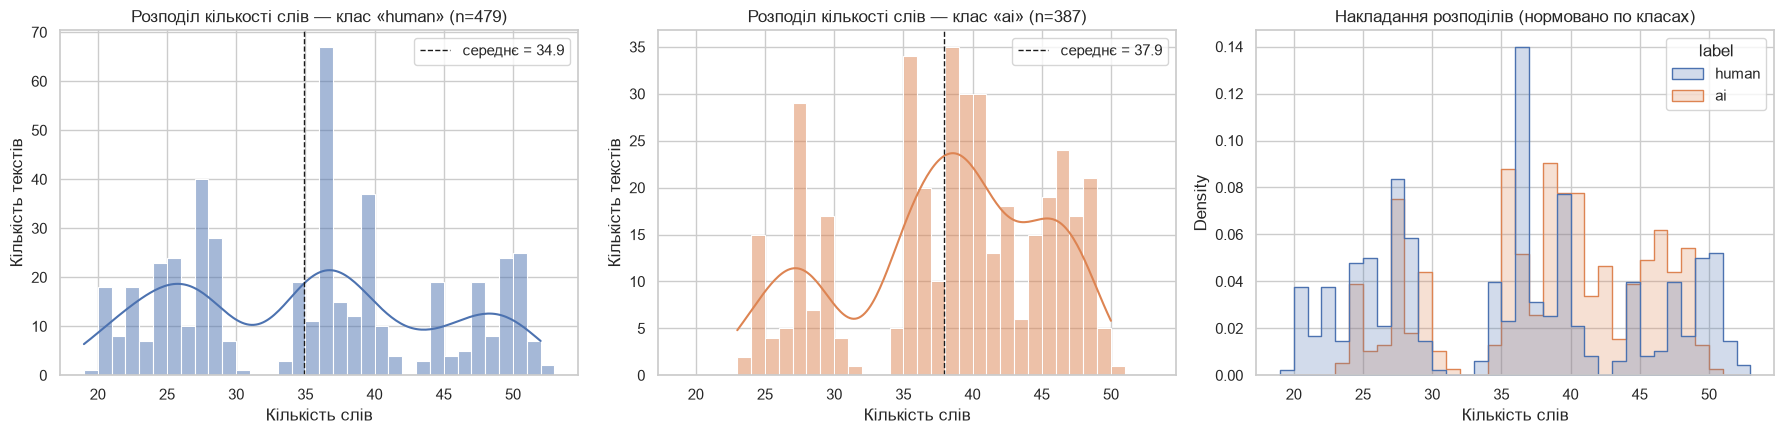

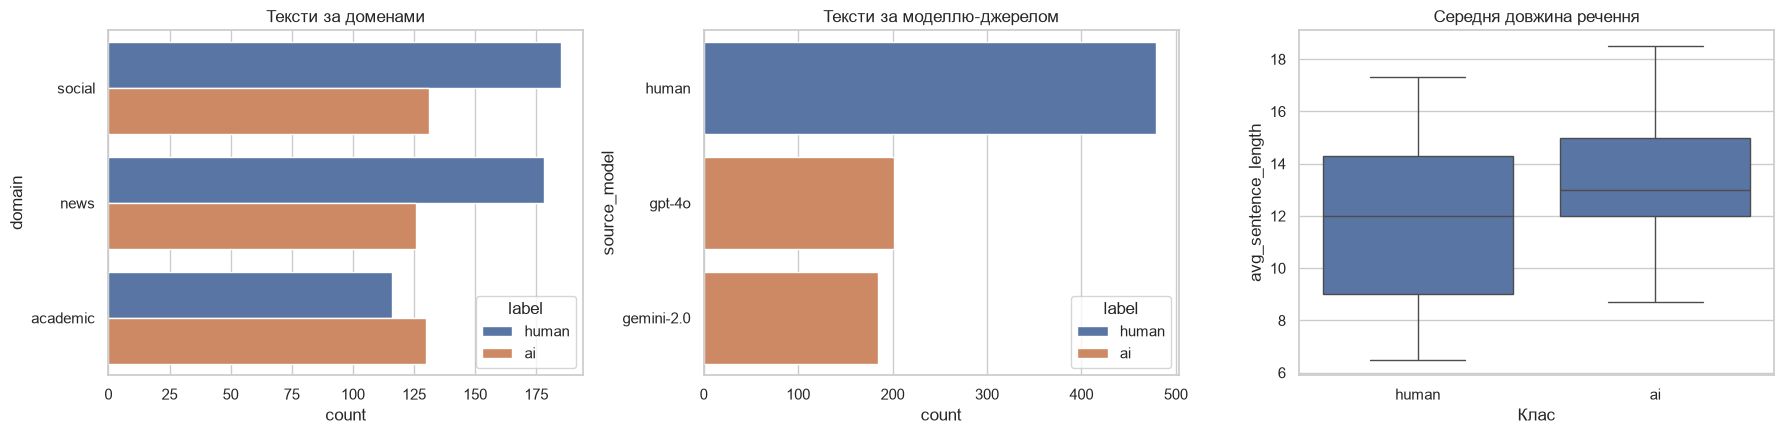

Розподіл клас × метод генерації (перевірка конфаундерів):


label,ai,human
generation_method,,
style_simulation,387,0
template+human_variation,0,479


Розподіл клас × домен (частки в межах домену, %):


label,ai,human
domain,,
academic,52.8,47.2
news,41.4,58.6
social,41.5,58.5


In [43]:
# ── Гістограми розподілу кількості слів для кожного класу ──
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharex=True)
bins = np.arange(df["word_count"].min(), df["word_count"].max() + 2, max(1, (df["word_count"].max() - df["word_count"].min()) // 25))
for ax, (lab, color) in zip(axes[:2], [("human", "#4C72B0"), ("ai", "#DD8452")]):
    sub = df[df.label == lab]
    sns.histplot(sub["word_count"], bins=bins, kde=True, color=color, ax=ax)
    ax.axvline(sub["word_count"].mean(), color="k", ls="--", lw=1, label=f"середнє = {sub['word_count'].mean():.1f}")
    ax.set_title(f"Розподіл кількості слів — клас «{lab}» (n={len(sub)})")
    ax.set_xlabel("Кількість слів"); ax.set_ylabel("Кількість текстів"); ax.legend()
sns.histplot(data=df, x="word_count", hue="label", hue_order=["human", "ai"], bins=bins, stat="density",
             common_norm=False, element="step", ax=axes[2])
axes[2].set_title("Накладання розподілів (нормовано по класах)")
axes[2].set_xlabel("Кількість слів")
plt.tight_layout(); plt.show()

# ── Домени та моделі-джерела ──
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=df, y="domain", hue="label", hue_order=["human", "ai"], order=df["domain"].value_counts().index, ax=axes[0])
axes[0].set_title("Тексти за доменами")
top_models = df["source_model"].value_counts().head(10).index
sns.countplot(data=df[df.source_model.isin(top_models)], y="source_model", hue="label", hue_order=["human", "ai"], order=top_models, ax=axes[1])
axes[1].set_title("Тексти за моделлю-джерелом")
sns.boxplot(data=df, x="label", y="avg_sentence_length", order=["human", "ai"], ax=axes[2])
axes[2].set_title("Середня довжина речення"); axes[2].set_xlabel("Клас")
plt.tight_layout(); plt.show()

print("Розподіл клас × метод генерації (перевірка конфаундерів):")
display(pd.crosstab(df["generation_method"], df["label"]))
print("Розподіл клас × домен (частки в межах домену, %):")
display((pd.crosstab(df["domain"], df["label"], normalize="index") * 100).round(1))

In [44]:
# ── Автоматичне резюме EDA ──
vc = df["label"].value_counts()
ratio = vc.max() / vc.min()
gm = pd.crosstab(df["generation_method"], df["label"])
perfect_gm = (gm.gt(0).sum(axis=1) == 1).all() and gm.shape[0] > 1
lines = [
    "### Резюме первинного аналізу (формується автоматично)",
    f"* **Обсяг:** після очищення лишилось **{len(df):,}** унікальних текстів ({vc.get('human', 0)} human / {vc.get('ai', 0)} AI; "
    f"співвідношення ≈ {ratio:.2f}:1). {'Дисбаланс помітний — тому окрім Accuracy використовуємо Macro F1 та Balanced Accuracy.' if ratio > 1.2 else 'Класи майже збалансовані.'}",
    f"* **Артефакти:** вилучено {n_before - len(df):,} рядків (дублікати, порожні/короткі тексти, конфліктні мітки, невалідні мітки).",
    f"* **Довжина:** середня кількість слів — human {df.loc[df.label=='human','word_count'].mean():.1f}, AI {df.loc[df.label=='ai','word_count'].mean():.1f} "
    f"(тест Манна–Вітні p = {p_len:.3g}) — {'довжина статистично відрізняється між класами, тож є потенційним «шорткатом».' if p_len < 0.05 else 'суттєвої різниці довжин не виявлено.'}",
    f"* **Короткі тексти:** медіана {df['word_count'].median():.0f} слів, тож майже кожен терм трапляється в документі 1 раз (tf ≈ const), "
    f"і TF-IDF працює переважно через IDF.",
    f"* **Конфаундери:** {'колонка generation_method ПОВНІСТЮ збігається з міткою класу (використовувати її як ознаку не можна — це витік), ' if perfect_gm else ''}"
    f"домени та моделі-джерела розподілені між класами нерівномірно (див. таблиці вище), тож частину сигналу може давати регістр/тема, а не «стиль ШІ».",
]
if FALLBACK_USED:
    lines.append("* ⚠️ **Дані синтетичні** — це лише тест працездатності коду.")
display(Markdown("\n".join(lines)))

### Резюме первинного аналізу (формується автоматично)
* **Обсяг:** після очищення лишилось **866** унікальних текстів (479 human / 387 AI; співвідношення ≈ 1.24:1). Дисбаланс помітний — тому окрім Accuracy використовуємо Macro F1 та Balanced Accuracy.
* **Артефакти:** вилучено 1,134 рядків (дублікати, порожні/короткі тексти, конфліктні мітки, невалідні мітки).
* **Довжина:** середня кількість слів — human 34.9, AI 37.9 (тест Манна–Вітні p = 8.78e-08) — довжина статистично відрізняється між класами, тож є потенційним «шорткатом».
* **Короткі тексти:** медіана 37 слів, тож майже кожен терм трапляється в документі 1 раз (tf ≈ const), і TF-IDF працює переважно через IDF.
* **Конфаундери:** колонка generation_method ПОВНІСТЮ збігається з міткою класу (використовувати її як ознаку не можна — це витік), домени та моделі-джерела розподілені між класами нерівномірно (див. таблиці вище), тож частину сигналу може давати регістр/тема, а не «стиль ШІ».

## Етап 2. Попередня обробка тексту (spaCy)

Конвеєр: **лематизація → видалення стоп-слів → видалення небуквених токенів → нижній регістр**. Обробка йде через `nlp.pipe()` із батчингом. Компоненти `parser` та `ner` вимкнено — для лематизації вони не потрібні, а обробка стає швидшою.

In [45]:
MODEL_NAME = "en_core_web_sm"
try:
    nlp = spacy.load(MODEL_NAME, disable=["parser", "ner"])
except OSError:
    print(f"Завантажуємо модель spaCy {MODEL_NAME} ...")
    subprocess.check_call([sys.executable, "-m", "spacy", "download", MODEL_NAME])
    nlp = spacy.load(MODEL_NAME, disable=["parser", "ner"])


def preprocess(text: str) -> list:
    '''Версія з методички для одного тексту (для демонстрації).'''
    doc = nlp(text)
    return [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]


N_PROCESS = 1   # 1 — найстабільніше (особливо на Windows/у Jupyter); можна збільшити для великих корпусів


def preprocess_texts(texts: Sequence[str], batch_size: int = 256) -> List[List[str]]:
    '''Пакетна обробка через nlp.pipe(): лема, нижній регістр, лише літерні нестоп-токени.'''
    result = []
    for doc in tqdm(nlp.pipe(texts, batch_size=batch_size, n_process=N_PROCESS),
                    total=len(texts), desc="spaCy", unit="текст"):
        result.append([t.lemma_.lower().strip() for t in doc
                       if t.is_alpha and not t.is_stop and t.lemma_.strip()])
    return result


df["tokens"] = preprocess_texts(df["text_content"].tolist(), batch_size=256)

# узгодженість із версією з методички
assert preprocess(df["text_content"].iloc[0]) == df["tokens"].iloc[0]

empty_after = int((df["tokens"].str.len() == 0).sum())
if empty_after:
    print(f"Вилучаємо {empty_after} документ(ів), що стали порожніми після обробки.")
    df = df[df["tokens"].str.len() > 0].reset_index(drop=True)

df["n_tokens"] = df["tokens"].str.len()
print(f"Документів: {len(df):,}; токенів загалом: {df['n_tokens'].sum():,}; "
      f"середня довжина після обробки: {df['n_tokens'].mean():.1f}")
display(df[["label", "text_content", "tokens"]].head(6))

spaCy: 100%|██████████| 866/866 [00:01<00:00, 750.57текст/s]


Документів: 866; токенів загалом: 18,589; середня довжина після обробки: 21.5


,label,text_content,tokens
0,human,can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. th...,"[talk, gene, edit, ethic, sec, feel, like, people, completely, miss, point, big, realize]"
1,human,update on election integrity concerns: it's complicated and anyone telling you otherwise is selling something. do yo...,"[update, election, integrity, concern, complicated, tell, sell, research]"
2,ai,"Analysts are closely watching developments related to climate change adaptation strategies, noting that recent event...","[analyst, closely, watch, development, relate, climate, change, adaptation, strategy, note, recent, event, mark, pot..."
3,human,"This paper examines genomic research breakthroughs through a critical lens, drawing on empirical evidence gathered ...","[paper, examine, genomic, research, breakthrough, critical, lens, draw, empirical, evidence, gather, year, period, f..."
4,ai,"Existing literature on student debt crisis has predominantly relied on cross-sectional designs, limiting causal infe...","[exist, literature, student, debt, crisis, predominantly, rely, cross, sectional, design, limit, causal, inference, ..."
5,ai,The concept of biodiversity loss occupies a contested space within contemporary scholarly discourse. Divergent theor...,"[concept, biodiversity, loss, occupy, contest, space, contemporary, scholarly, discourse, divergent, theoretical, fr..."


## Етап 3. Навчання моделі FastText (gensim)

Параметри з методички: `vector_size=100, window=5, min_count=2, sg=1 (skip-gram), workers=4, seed=42`; додатково `epochs=10`.
> Примітка: при `workers>1` gensim не гарантує побітової відтворюваності, тому цифри можуть трохи відрізнятися між запусками.

In [46]:
# Сумісність старих gensim зі свіжим scipy (де прибрали scipy.linalg.triu).
try:
    import scipy.linalg
    if not hasattr(scipy.linalg, "triu"):
        scipy.linalg.triu = np.triu
except ImportError:
    pass
from gensim.models import FastText

corpus = df["tokens"].tolist()

fasttext_model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=SEED,
    epochs=10,
)
wv = fasttext_model.wv
print(f"Розмір словника FastText (min_count=2): {len(wv):,}")
all_terms = {t for doc in corpus for t in doc}
print(f"Унікальних лем у корпусі: {len(all_terms):,}; з них поза словником (трапляються 1 раз): {len(all_terms - set(wv.key_to_index)):,}")

Розмір словника FastText (min_count=2): 508
Унікальних лем у корпусі: 510; з них поза словником (трапляються 1 раз): 2


In [47]:
# ── Демонстрація: найближчі слова та робота з OOV ──
for w in wv.index_to_key[:4]:
    print(f"{w!r:>16} → ", ", ".join(f"{n} ({s:.2f})" for n, s in wv.most_similar(w, topn=5)))

oov_word = "climatepolicy"
print(f"\nOOV-слово {oov_word!r}: у словнику = {oov_word in wv.key_to_index}")
oov_vec = wv.get_vector(oov_word)
print(f"Вектор з символьних n-грам: форма {oov_vec.shape}, скінченний = {bool(np.isfinite(oov_vec).all())}")

base = wv.index_to_key[0]
variant = base + "ness"        # «вигадана» словоформа з тим самим коренем
sim = float(wv.similarity(base, variant))
print(f"Косинусна подібність {base!r} ↔ OOV-варіант {variant!r}: {sim:.3f} "
      "(спільні n-грами дають осмислену близькість; у Word2Vec тут був би KeyError).")

     'challenge' →  yes (0.70), age (0.67), detail (0.67), formal (0.67), hopeful (0.67)
      'official' →  formal (0.83), statement (0.82), release (0.82), hour (0.79), tuesday (0.79)
         'study' →  identify (0.79), jurisdiction (0.78), publish (0.77), good (0.77), span (0.76)
          'come' →  keep (0.83), idk (0.83), time (0.82), week (0.79), announcement (0.76)

OOV-слово 'climatepolicy': у словнику = False
Вектор з символьних n-грам: форма (100,), скінченний = True
Косинусна подібність 'challenge' ↔ OOV-варіант 'challengeness': 0.910 (спільні n-грами дають осмислену близькість; у Word2Vec тут був би KeyError).


## Етап 4. Векторизація документів

Реалізовано два методи агрегації (рівняння (5) та (6)). TF-IDF рахується **явно за формулами (3)–(4)**: $\text{tf}(t,d)=\dfrac{\text{count}(t,d)}{m_d}$, $\ \text{idf}(t)=\ln\dfrac{|D|}{\text{df}(t)}$.
Якщо сума ваг документа дорівнює нулю (усі терми є в кожному документі, idf = 0), використовується звичайне середнє — такі випадки лічильник покаже нижче.

In [ ]:
# ── TF-IDF за формулами (3)–(4) ──
N_DOCS = len(df)
# CountVectorizer будує матрицю підрахунків: рядки це документи, стовпчики це слова, а в клітинці стоїть, скільки разів слово трапилось у документі
cv = CountVectorizer(analyzer=lambda doc: doc)
count_matrix = cv.fit_transform(df["tokens"])             # (документи × терми)
terms = np.array(cv.get_feature_names_out())
doc_freq = np.asarray((count_matrix > 0).sum(axis=0)).ravel()
idf_values = np.log(N_DOCS / doc_freq)
idf = dict(zip(terms, idf_values))
DEFAULT_IDF = float(np.log(N_DOCS))                       # для термів, яких не було при обчисленні IDF

doc_len = np.asarray(count_matrix.sum(axis=1)).ravel()
tfidf_matrix = (sparse.diags(1.0 / np.maximum(doc_len, 1)) @ count_matrix @ sparse.diags(idf_values)).tocsr()


def doc_tfidf_scores(tokens: Sequence[str], idf_map: Dict[str, float], default_idf: float) -> Dict[str, float]:
    '''tfidf(t, d) = tf(t, d) * idf(t) для кожного терма документа.'''
    m = len(tokens)
    return {t: (c / m) * idf_map.get(t, default_idf) for t, c in Counter(tokens).items()} if m else {}


# перевірка: матриця та словникова реалізація збігаються
_row = tfidf_matrix.getrow(0)
_check = doc_tfidf_scores(df["tokens"].iloc[0], idf, DEFAULT_IDF)
assert all(np.isclose(_check[terms[j]], v) for j, v in zip(_row.indices, _row.data))
print(f"TF-IDF готовий: матриця {tfidf_matrix.shape}, термів із idf = 0: {int((idf_values == 0).sum())}")

TF-IDF готовий: матриця (866, 510), термів із idf = 0: 0


In [49]:
# ── Функції агрегації (за методичкою) ──
USE_SUBWORDS = True   # True: токени поза словником отримують вектор із символьних n-грам (суть FastText)
pool_stats = {"zero_weight_fallback": 0}


def word_vector(token: str, model) -> np.ndarray:
    cache = model.__dict__.setdefault("_wv_cache", {})
    if token not in cache:
        cache[token] = model.wv.get_vector(token)         # для OOV — сума векторів n-грам
    return cache[token]


def _usable(tokens, model):
    return [t for t in tokens if USE_SUBWORDS or t in model.wv.key_to_index]


def mean_pooling(tokens: Sequence[str], model) -> np.ndarray:
    tokens = _usable(tokens, model)
    if not tokens:
        return np.zeros(model.vector_size)
    return np.mean([word_vector(t, model) for t in tokens], axis=0)


def tfidf_weighted_pooling(tokens: Sequence[str], model, tfidf_scores: Dict[str, float]) -> np.ndarray:
    tokens = _usable(tokens, model)
    if not tokens:
        return np.zeros(model.vector_size)
    weights = np.array([tfidf_scores.get(t, 0.0) for t in tokens], dtype=float)
    if weights.sum() <= 0:
        pool_stats["zero_weight_fallback"] += 1
        return mean_pooling(tokens, model)
    vectors = np.array([word_vector(t, model) for t in tokens])
    return np.average(vectors, axis=0, weights=weights)   # Σ w_i v_i / Σ w_i  (формула 6)


def vectorize_documents(docs: Sequence[Sequence[str]], model, idf_map, default_idf):
    X_m = np.zeros((len(docs), model.vector_size), dtype=np.float32)
    X_t = np.zeros_like(X_m)
    for i, tokens in enumerate(tqdm(docs, desc="Агрегація", unit="док")):
        X_m[i] = mean_pooling(tokens, model)
        X_t[i] = tfidf_weighted_pooling(tokens, model, doc_tfidf_scores(tokens, idf_map, default_idf))
    return X_m, X_t


X_mean, X_tfidf = vectorize_documents(df["tokens"].tolist(), fasttext_model, idf, DEFAULT_IDF)
y = df["label"].map({"human": 0, "ai": 1}).to_numpy(dtype=int)
REPS = {"Mean pooling": X_mean, "TF-IDF weighted": X_tfidf}
AGG_M, AGG_T = list(REPS)
print(f"X_mean: {X_mean.shape}; X_tfidf: {X_tfidf.shape}; y: {y.shape}; "
      f"fallback на нульові ваги: {pool_stats['zero_weight_fallback']}")

Агрегація: 100%|██████████| 866/866 [00:00<00:00, 23423.10док/s]

X_mean: (866, 100); X_tfidf: (866, 100); y: (866,); fallback на нульові ваги: 0


In [50]:
# ── Ілюстрація: які слова отримують найбільшу вагу в документі ──
def show_weights(i, k=8):
    toks = df["tokens"].iloc[i]
    sc = doc_tfidf_scores(toks, idf, DEFAULT_IDF)
    tot = sum(sc[t] for t in toks)
    top = sorted(sc.items(), key=lambda kv: -kv[1])[:k]
    low = sorted(sc.items(), key=lambda kv: kv[1])[:k]
    print(f"Документ #{i} ({df['label'].iloc[i]}), {len(toks)} токенів")
    print("  найбільші ваги:", ", ".join(f"{t} ({100 * sc[t] * toks.count(t) / tot:.0f}%)" for t, _ in top))
    print("  найменші ваги :", ", ".join(f"{t} ({100 * sc[t] * toks.count(t) / tot:.0f}%)" for t, _ in low))
    print(f"  (при Mean Pooling кожен токен має вагу {100 / len(toks):.1f}%)")

show_weights(int(np.where(y == 1)[0][0]))
show_weights(int(np.where(y == 0)[0][0]))

Документ #2 (ai), 31 токенів
  найбільші ваги: closely (4%), watch (4%), relate (4%), note (4%), event (4%), mark (4%), turning (4%), stand (4%)
  найменші ваги : long (2%), remain (2%), point (2%), issue (3%), development (3%), underscore (3%), solution (3%), change (3%)
  (при Mean Pooling кожен токен має вагу 3.2%)
Документ #0 (human), 13 токенів
  найбільші ваги: edit (9%), sec (8%), feel (8%), completely (8%), miss (8%), big (8%), realize (8%), gene (8%)
  найменші ваги : point (5%), people (6%), like (7%), talk (7%), gene (8%), ethic (8%), sec (8%), feel (8%)
  (при Mean Pooling кожен токен має вагу 7.7%)


## Етап 5. Навчання та оцінка класифікаторів

Для кожного методу агрегації навчаємо три класифікатори на **тому самому** стратифікованому поділі 80/20 (`random_state=42`).
* **Основний експеримент** — точно за методичкою, *без* масштабування ознак.
* **Розширення** — ті самі моделі зі `StandardScaler` усередині пайплайна (fit лише на train). Воно потрібне, щоб відокремити вплив *масштабу ознак* від впливу самої агрегації (особливо для KNN і SVM-RBF, які чутливі до метрики).

In [51]:
idx_all = np.arange(len(y))
idx_train, idx_test = train_test_split(idx_all, test_size=0.2, random_state=SEED, stratify=y)
y_train, y_test = y[idx_train], y[idx_test]
print(f"train: {len(idx_train)} (AI {y_train.mean():.1%}) | test: {len(idx_test)} (AI {y_test.mean():.1%})")

SC0, SC1 = "Без масштабування (як у методичці)", "StandardScaler"
CLF_NAMES = ["SVM (RBF)", "LogReg", "KNN (k=5)"]


def make_classifiers(scale: bool = False, probability: bool = True) -> Dict[str, object]:
    wrap = (lambda est: make_pipeline(StandardScaler(), est)) if scale else (lambda est: est)
    return {
        "SVM (RBF)": wrap(SVC(kernel="rbf", probability=probability, random_state=SEED)),
        "LogReg": wrap(LogisticRegression(max_iter=1000, random_state=SEED)),
        "KNN (k=5)": wrap(KNeighborsClassifier(n_neighbors=5)),
    }


def evaluate_all(reps: Dict[str, np.ndarray], scale: bool, tr=None, te=None):
    tr = idx_train if tr is None else tr
    te = idx_test if te is None else te
    rows, cms = [], {}
    for agg, X in reps.items():
        for name, clf in make_classifiers(scale).items():
            clf.fit(X[tr], y[tr])
            pred = clf.predict(X[te])
            proba = clf.predict_proba(X[te])[:, 1]
            cms[(scale, agg, name)] = confusion_matrix(y[te], pred, labels=[0, 1])
            rows.append({
                "Масштабування": SC1 if scale else SC0, "Агрегація": agg, "Класифікатор": name,
                "Macro F1": f1_score(y[te], pred, average="macro"),
                "Accuracy": accuracy_score(y[te], pred),
                "Balanced Accuracy": balanced_accuracy_score(y[te], pred),
                "ROC-AUC": roc_auc_score(y[te], proba),
            })
    return pd.DataFrame(rows), cms


res0, cms0 = evaluate_all(REPS, scale=False)
res1, cms1 = evaluate_all(REPS, scale=True)
results_all = pd.concat([res0, res1], ignore_index=True)
confusions = {**cms0, **cms1}

METRICS = ["Macro F1", "Accuracy", "Balanced Accuracy", "ROC-AUC"]
fmt = {m: "{:.3f}" for m in METRICS}
print("ОСНОВНИЙ ЕКСПЕРИМЕНТ (як у методичці, без масштабування):")
display(res0.drop(columns="Масштабування").style.format(fmt).background_gradient(subset=["Macro F1", "ROC-AUC"], cmap="YlGn"))
print("РОЗШИРЕННЯ: ті самі моделі зі StandardScaler:")
display(res1.drop(columns="Масштабування").style.format(fmt).background_gradient(subset=["Macro F1", "ROC-AUC"], cmap="YlGn"))

train: 692 (AI 44.7%) | test: 174 (AI 44.8%)
ОСНОВНИЙ ЕКСПЕРИМЕНТ (як у методичці, без масштабування):


,Агрегація,Класифікатор,Macro F1,Accuracy,Balanced Accuracy,ROC-AUC
0,Mean pooling,SVM (RBF),1.000,1.000,1.000,1.000
1,Mean pooling,LogReg,0.948,0.948,0.947,0.996
2,Mean pooling,KNN (k=5),1.000,1.000,1.000,1.000
3,TF-IDF weighted,SVM (RBF),1.000,1.000,1.000,1.000
4,TF-IDF weighted,LogReg,0.959,0.960,0.959,0.997
5,TF-IDF weighted,KNN (k=5),1.000,1.000,1.000,1.000


РОЗШИРЕННЯ: ті самі моделі зі StandardScaler:


,Агрегація,Класифікатор,Macro F1,Accuracy,Balanced Accuracy,ROC-AUC
0,Mean pooling,SVM (RBF),1.000,1.000,1.000,1.000
1,Mean pooling,LogReg,1.000,1.000,1.000,1.000
2,Mean pooling,KNN (k=5),1.000,1.000,1.000,1.000
3,TF-IDF weighted,SVM (RBF),1.000,1.000,1.000,1.000
4,TF-IDF weighted,LogReg,1.000,1.000,1.000,1.000
5,TF-IDF weighted,KNN (k=5),1.000,1.000,1.000,1.000


Різниця метрик на holdout-вибірці (TF-IDF − Mean):


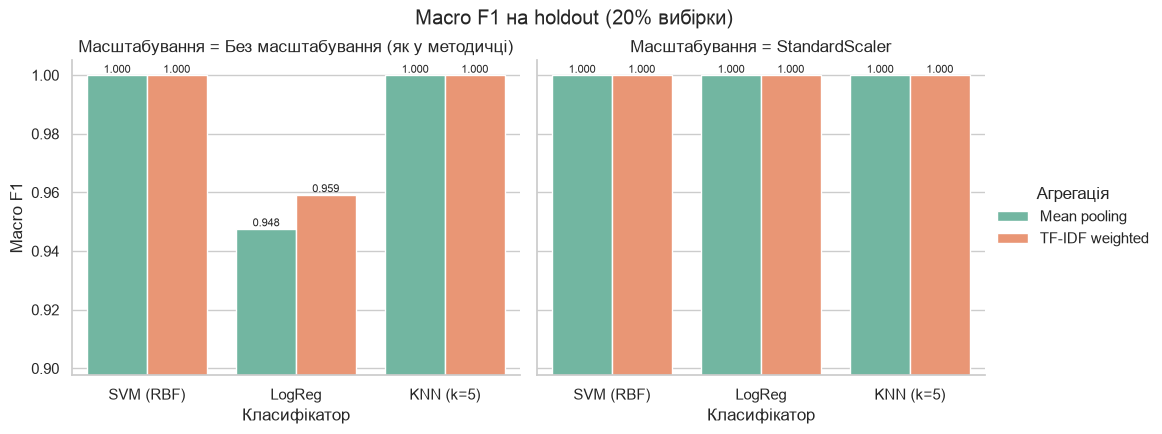

In [ ]:
# ── Δ = TF-IDF − Mean (holdout) Таблиця різниць (TF-IDF мінус Mean) ── 
piv = results_all.pivot_table(index=["Масштабування", "Класифікатор"], columns="Агрегація", values=METRICS)
delta_holdout = pd.DataFrame({m: piv[(m, AGG_T)] - piv[(m, AGG_M)] for m in METRICS})
print("Різниця метрик на holdout-вибірці (TF-IDF − Mean):")
display(delta_holdout.style.format("{:+.3f}").background_gradient(cmap="RdYlGn", vmin=-0.05, vmax=0.05))

g = sns.catplot(data=results_all, kind="bar", x="Класифікатор", y="Macro F1", hue="Агрегація",
                col="Масштабування", order=CLF_NAMES, height=4.2, aspect=1.2, palette="Set2")
lo = max(0.0, results_all["Macro F1"].min() - 0.05)
g.set(ylim=(lo, 1.005))
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8)
g.figure.suptitle("Macro F1 на holdout (20% вибірки)", y=1.03)
plt.show()

### Стійкість висновків: повторна стратифікована крос-валідація (5 фолдів × 2 повтори)
Тест із ~200 документів дає великий розкид оцінок, а різниця між агрегаціями часто менша за шум одного поділу. Тому додатково порівнюємо методи на **одних і тих самих** 10 фолдах (парне порівняння). *Примітка:* FastText та IDF тут навчені на всьому корпусі (без міток), а строга перевірка без цього витоку подана нижче.

In [53]:
cv_splitter = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
cv_fold_scores = {}
for scale in (False, True):
    for agg, X in tqdm(REPS.items(), desc=f"CV, scale={scale}", leave=False):
        for name, clf in make_classifiers(scale, probability=False).items():   # predict() не залежить від probability
            cv_fold_scores[(scale, agg, name)] = cross_val_score(clf, X, y, cv=cv_splitter, scoring="f1_macro")

cv_rows, cv_delta_rows = [], []
for scale in (False, True):
    for name in CLF_NAMES:
        s_m, s_t = cv_fold_scores[(scale, AGG_M, name)], cv_fold_scores[(scale, AGG_T, name)]
        d = s_t - s_m
        for agg, s in ((AGG_M, s_m), (AGG_T, s_t)):
            cv_rows.append({"Масштабування": SC1 if scale else SC0, "Класифікатор": name, "Агрегація": agg,
                            "Macro F1 (CV, середнє)": s.mean(), "± std": s.std()})
        cv_delta_rows.append({"Масштабування": SC1 if scale else SC0, "scale": scale, "Класифікатор": name,
                              "Δ Macro F1 (середнє)": d.mean(), "Δ std": d.std(),
                              "фолдів TF-IDF краще": int((d > 1e-12).sum()),
                              "нічия": int((np.abs(d) <= 1e-12).sum()),
                              "фолдів Mean краще": int((d < -1e-12).sum())})
cv_summary = pd.DataFrame(cv_rows)
cv_delta = pd.DataFrame(cv_delta_rows)
display(cv_summary.style.format({"Macro F1 (CV, середнє)": "{:.3f}", "± std": "{:.3f}"}))
display(cv_delta.drop(columns="scale").style.format({"Δ Macro F1 (середнє)": "{:+.4f}", "Δ std": "{:.4f}"}))

,Масштабування,Класифікатор,Агрегація,"Macro F1 (CV, середнє)",± std
0,Без масштабування (як у методичці),SVM (RBF),Mean pooling,1.000,0.000
1,Без масштабування (як у методичці),SVM (RBF),TF-IDF weighted,1.000,0.000
2,Без масштабування (як у методичці),LogReg,Mean pooling,0.949,0.017
3,Без масштабування (як у методичці),LogReg,TF-IDF weighted,0.952,0.017
4,Без масштабування (як у методичці),KNN (k=5),Mean pooling,1.000,0.000
5,Без масштабування (як у методичці),KNN (k=5),TF-IDF weighted,1.000,0.000
6,StandardScaler,SVM (RBF),Mean pooling,1.000,0.000
7,StandardScaler,SVM (RBF),TF-IDF weighted,1.000,0.000
8,StandardScaler,LogReg,Mean pooling,0.998,0.003
9,StandardScaler,LogReg,TF-IDF weighted,0.998,0.003


,Масштабування,Класифікатор,Δ Macro F1 (середнє),Δ std,фолдів TF-IDF краще,нічия,фолдів Mean краще
0,Без масштабування (як у методичці),SVM (RBF),+0.0000,0.0000,0,10,0
1,Без масштабування (як у методичці),LogReg,+0.0029,0.0060,4,5,1
2,Без масштабування (як у методичці),KNN (k=5),+0.0000,0.0000,0,10,0
3,StandardScaler,SVM (RBF),+0.0000,0.0000,0,10,0
4,StandardScaler,LogReg,+0.0000,0.0037,2,6,2
5,StandardScaler,KNN (k=5),+0.0000,0.0000,0,10,0


### Геометрична діагностика векторних просторів
Щоб відповісти на питання про зміну геометрії та чутливість KNN, порівнюємо два простори кількісно (на підвибірці до 1500 документів):
* **середня косинусна подібність** між документами — міра *анізотропії* (чим вона ближча до 1, тим більше всі вектори «дивляться в один бік»);
* **коефіцієнт варіації відстаней** та **контраст сусідства** $\bar d_{\text{NN}}/\bar d$ (середня відстань до найближчого сусіда / середня відстань між усіма парами) — ознаки *концентрації відстаней* (прокляття розмірності: коли коефіцієнт варіації малий, а контраст сусідства близький до 1, «найближчий» сусід майже не відрізняється від «випадкового»);
* **частка дисперсії PC1/топ-10** та **ефективна розмірність** (participation ratio) — наскільки дисперсія зосереджена в кількох напрямках;
* **відношення середніх міжкласових до внутрішньокласових відстаней** та **silhouette** за мітками класів;
* **чистота 5-NN** — частка 5 найближчих сусідів, що мають ту саму мітку (прямий предиктор якості KNN).

In [54]:
def geometry_report(X: np.ndarray, labels: np.ndarray, max_docs: int = 1500, seed: int = SEED) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=min(len(X), max_docs), replace=False)
    Xs, ys = X[idx].astype(float), labels[idx]
    D = pairwise_distances(Xs)
    iu = np.triu_indices_from(D, k=1)
    d = D[iu]
    norms = np.linalg.norm(Xs, axis=1)
    Xn = Xs / np.maximum(norms[:, None], 1e-12)
    cos = (Xn @ Xn.T)[iu]
    same = (ys[:, None] == ys[None, :])[iu]
    ev = PCA().fit(Xs).explained_variance_ratio_
    D_off = D + np.diag(np.full(len(Xs), np.inf))
    d_min = D_off.min(axis=1)

    def purity(Z, k=5):
        nn = NearestNeighbors(n_neighbors=k + 1).fit(Z)
        nb = nn.kneighbors(Z, return_distance=False)[:, 1:]
        return float((ys[nb] == ys[:, None]).mean())

    return {
        "Середня норма вектора": norms.mean(),
        "Коеф. варіації норм (std/mean)": norms.std() / norms.mean(),
        "Середня косинусна подібність": cos.mean(),
        "Коеф. варіації відстаней (std/mean)": d.std() / d.mean(),
        "Контраст сусідства (d найближчого / d середня)": float(d_min.mean() / d.mean()),
        "Частка дисперсії PC1": ev[0],
        "Частка дисперсії топ-10 PC": ev[:10].sum(),
        "Ефективна розмірність (participation ratio)": 1.0 / np.sum(ev ** 2),
        "Відстань між класами / всередині класів": d[~same].mean() / d[same].mean(),
        "Silhouette за класами (евкл.)": silhouette_score(Xs, ys),
        "Silhouette за класами (косин.)": silhouette_score(Xs, ys, metric="cosine"),
        "Чистота 5-NN (без масштабування)": purity(Xs),
        "Чистота 5-NN (після StandardScaler)": purity(StandardScaler().fit_transform(Xs)),
    }


geom_df = pd.DataFrame({agg: geometry_report(X, y) for agg, X in REPS.items()})
geom_df["Зміна (TF-IDF − Mean)"] = geom_df[AGG_T] - geom_df[AGG_M]
display(geom_df.style.format("{:.4f}"))

,Mean pooling,TF-IDF weighted,Зміна (TF-IDF − Mean)
Середня норма вектора,2.9458,2.9620,0.0161
Коеф. варіації норм (std/mean),0.0769,0.0752,-0.0017
Середня косинусна подібність,0.6662,0.6621,-0.0041
Коеф. варіації відстаней (std/mean),0.2057,0.2021,-0.0037
Контраст сусідства (d найближчого / d середня),0.1025,0.1057,0.0032
Частка дисперсії PC1,0.1651,0.1571,-0.0080
Частка дисперсії топ-10 PC,0.8090,0.8021,-0.0069
Ефективна розмірність (participation ratio),11.8676,12.3096,0.4421
Відстань між класами / всередині класів,1.0426,1.0448,0.0022
Silhouette за класами (евкл.),0.0442,0.0455,0.0013


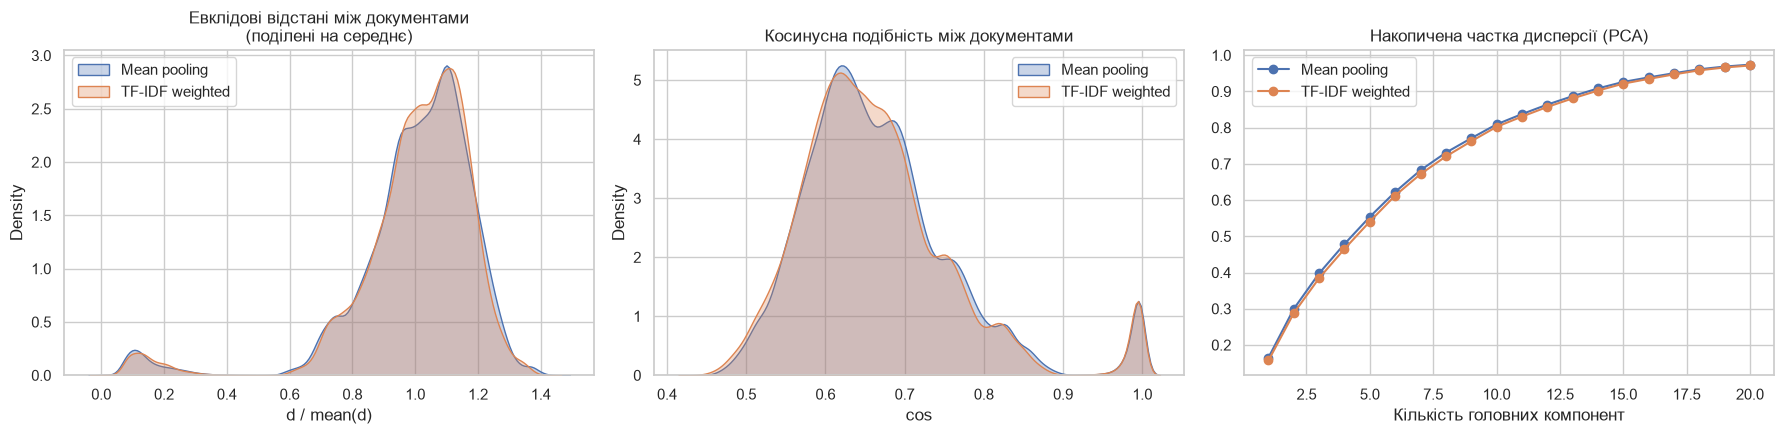

In [55]:
# ── Візуалізація геометрії: розподіл відстаней, косинусної подібності та спектр PCA ──
rng = np.random.default_rng(SEED)
sub = rng.choice(len(y), size=min(len(y), 1200), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for agg, X in REPS.items():
    Xs = X[sub].astype(float)
    d = pairwise_distances(Xs)[np.triu_indices(len(Xs), k=1)]
    sns.kdeplot(d / d.mean(), label=agg, ax=axes[0], fill=True, alpha=0.3)
    Xn = Xs / np.maximum(np.linalg.norm(Xs, axis=1, keepdims=True), 1e-12)
    sns.kdeplot((Xn @ Xn.T)[np.triu_indices(len(Xs), k=1)], label=agg, ax=axes[1], fill=True, alpha=0.3)
    axes[2].plot(np.arange(1, 21), np.cumsum(PCA(n_components=20).fit(Xs).explained_variance_ratio_), marker="o", label=agg)
axes[0].set_title("Евклідові відстані між документами\n(поділені на середнє)"); axes[0].set_xlabel("d / mean(d)"); axes[0].legend()
axes[1].set_title("Косинусна подібність між документами"); axes[1].set_xlabel("cos"); axes[1].legend()
axes[2].set_title("Накопичена частка дисперсії (PCA)"); axes[2].set_xlabel("Кількість головних компонент"); axes[2].legend()
plt.tight_layout(); plt.show()

## Етап 6. Візуалізація та аналіз

### 6.1. t-SNE проєкції (окремо для Mean Pooling і TF-IDF Weighted Mean)
t-SNE — нелінійна візуалізація: відстані між кластерами та їхні розміри на ній інтерпретувати кількісно **не можна**. Тому додатково рахуємо silhouette і чистоту 5-NN *у 2D-проєкції* як грубу числову підтримку візуального враження.

t-SNE: 100%|██████████| 2/2 [00:03<00:00,  1.52s/it]


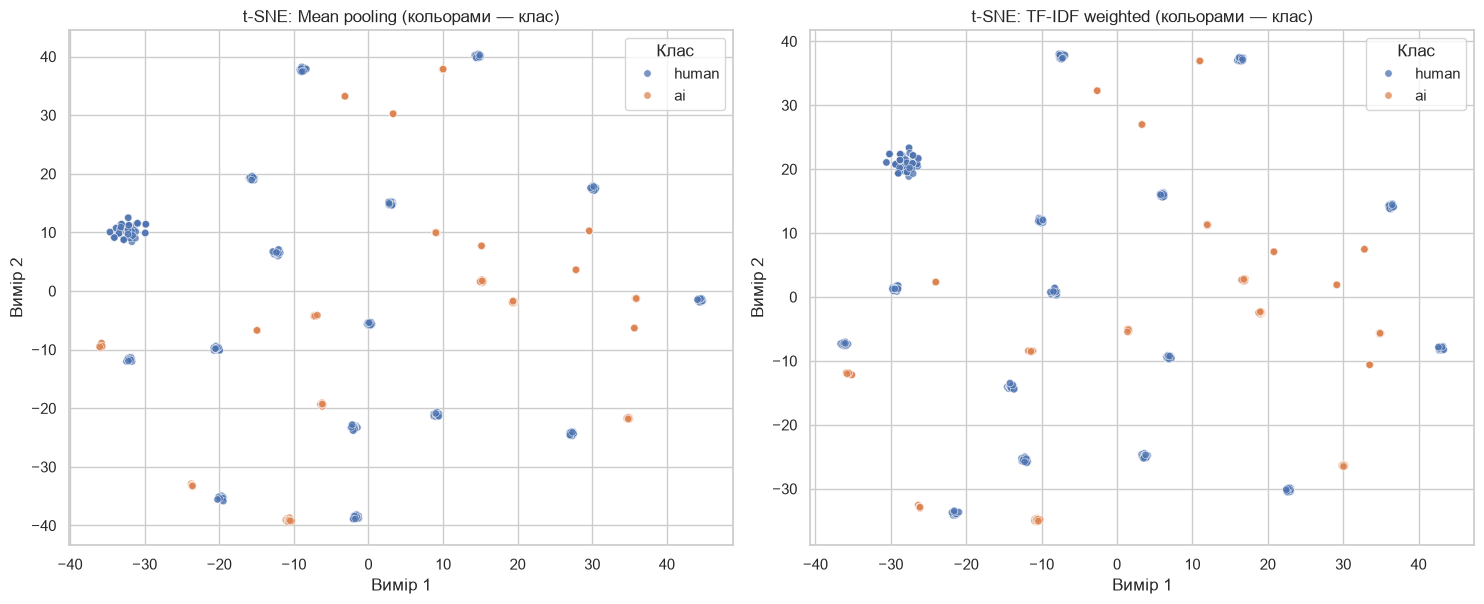

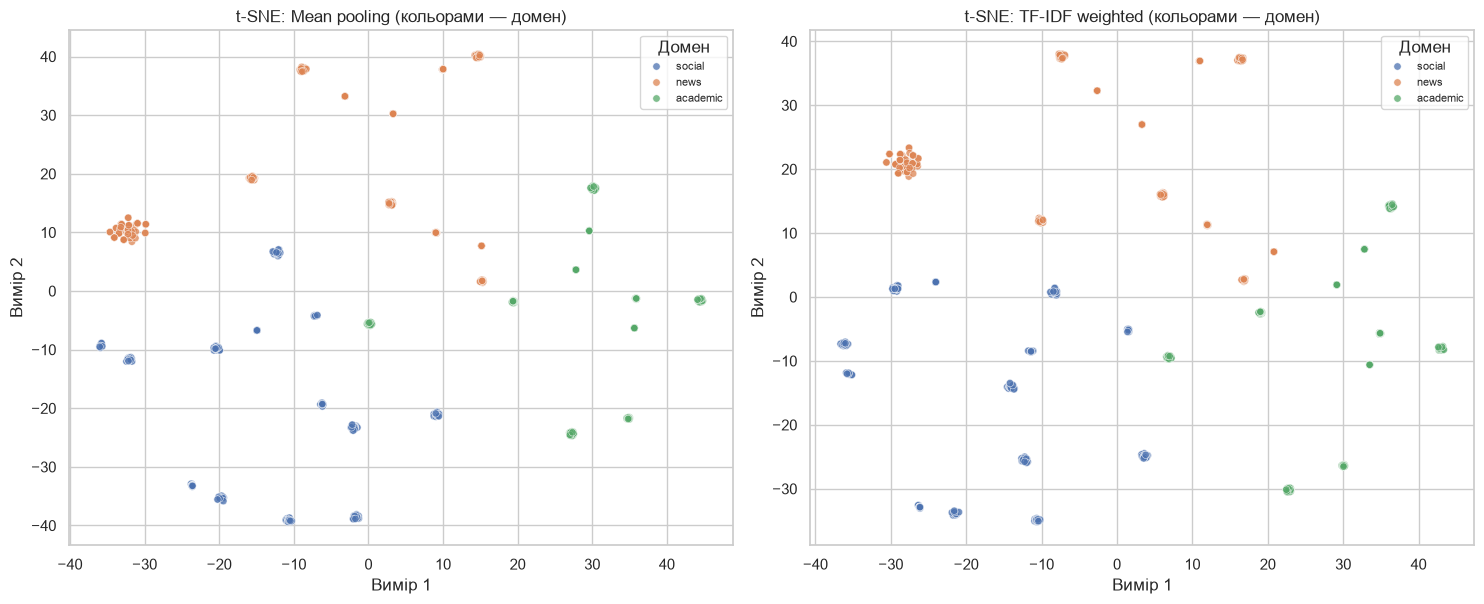

,Silhouette 2D (клас),Чистота 5-NN 2D (клас),Silhouette 2D (домен),Чистота 5-NN 2D (домен)
Агрегація,,,,
Mean pooling,0.052,1.000,0.372,1.000
TF-IDF weighted,0.056,1.000,0.406,1.000


In [56]:
MAX_TSNE = 2000
if len(df) > MAX_TSNE:
    _, tsne_idx = train_test_split(np.arange(len(df)), test_size=MAX_TSNE / len(df), random_state=SEED, stratify=y)
else:
    tsne_idx = np.arange(len(df))
perplexity = min(30, max(2, (len(tsne_idx) - 1) // 3))

tsne_coords = {}
for agg, X in tqdm(REPS.items(), desc="t-SNE"):
    tsne_coords[agg] = TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto",
                            random_state=SEED).fit_transform(X[tsne_idx])

y_tsne = y[tsne_idx]
dom_codes, dom_names = pd.factorize(df["domain"].iloc[tsne_idx])
has_domain = len(dom_names) > 1 and not (len(dom_names) == 1 and dom_names[0] == "unknown")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, agg in zip(axes, REPS):
    c = tsne_coords[agg]
    plot_df = pd.DataFrame({"x": c[:, 0], "y": c[:, 1], "Клас": [LABEL_NAMES[v] for v in y_tsne]})
    sns.scatterplot(data=plot_df, x="x", y="y", hue="Клас", hue_order=["human", "ai"],
                    palette={"human": "#4C72B0", "ai": "#DD8452"}, alpha=0.75, s=28, ax=ax)
    ax.set_title(f"t-SNE: {agg} (кольорами — клас)"); ax.set_xlabel("Вимір 1"); ax.set_ylabel("Вимір 2")
plt.tight_layout(); plt.show()

if has_domain:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
    for ax, agg in zip(axes, REPS):
        c = tsne_coords[agg]
        sns.scatterplot(x=c[:, 0], y=c[:, 1], hue=df["domain"].iloc[tsne_idx].to_numpy(), alpha=0.75, s=28, ax=ax)
        ax.set_title(f"t-SNE: {agg} (кольорами — домен)"); ax.set_xlabel("Вимір 1"); ax.set_ylabel("Вимір 2")
        ax.legend(title="Домен", fontsize=8)
    plt.tight_layout(); plt.show()


def embedding_quality(coords, labels, k=5):
    nb = NearestNeighbors(n_neighbors=k + 1).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]
    return silhouette_score(coords, labels), float((labels[nb] == labels[:, None]).mean())


tsne_rows = []
for agg in REPS:
    s_l, p_l = embedding_quality(tsne_coords[agg], y_tsne)
    row = {"Агрегація": agg, "Silhouette 2D (клас)": s_l, "Чистота 5-NN 2D (клас)": p_l}
    if has_domain:
        s_d, p_d = embedding_quality(tsne_coords[agg], dom_codes)
        row.update({"Silhouette 2D (домен)": s_d, "Чистота 5-NN 2D (домен)": p_d})
    tsne_rows.append(row)
tsne_quality = pd.DataFrame(tsne_rows).set_index("Агрегація")
display(tsne_quality.style.format("{:.3f}"))

### 6.2. Матриці плутанини для кожного класифікатора

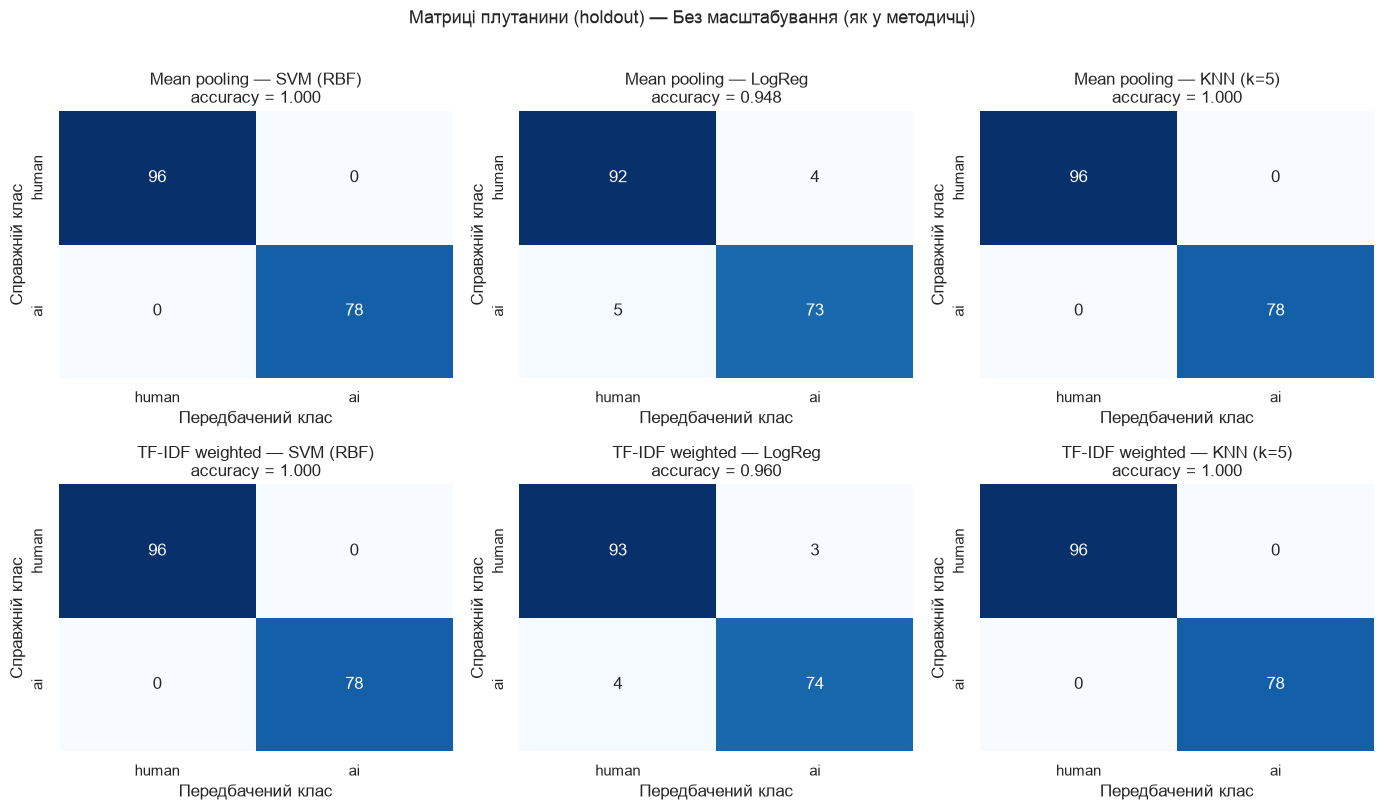

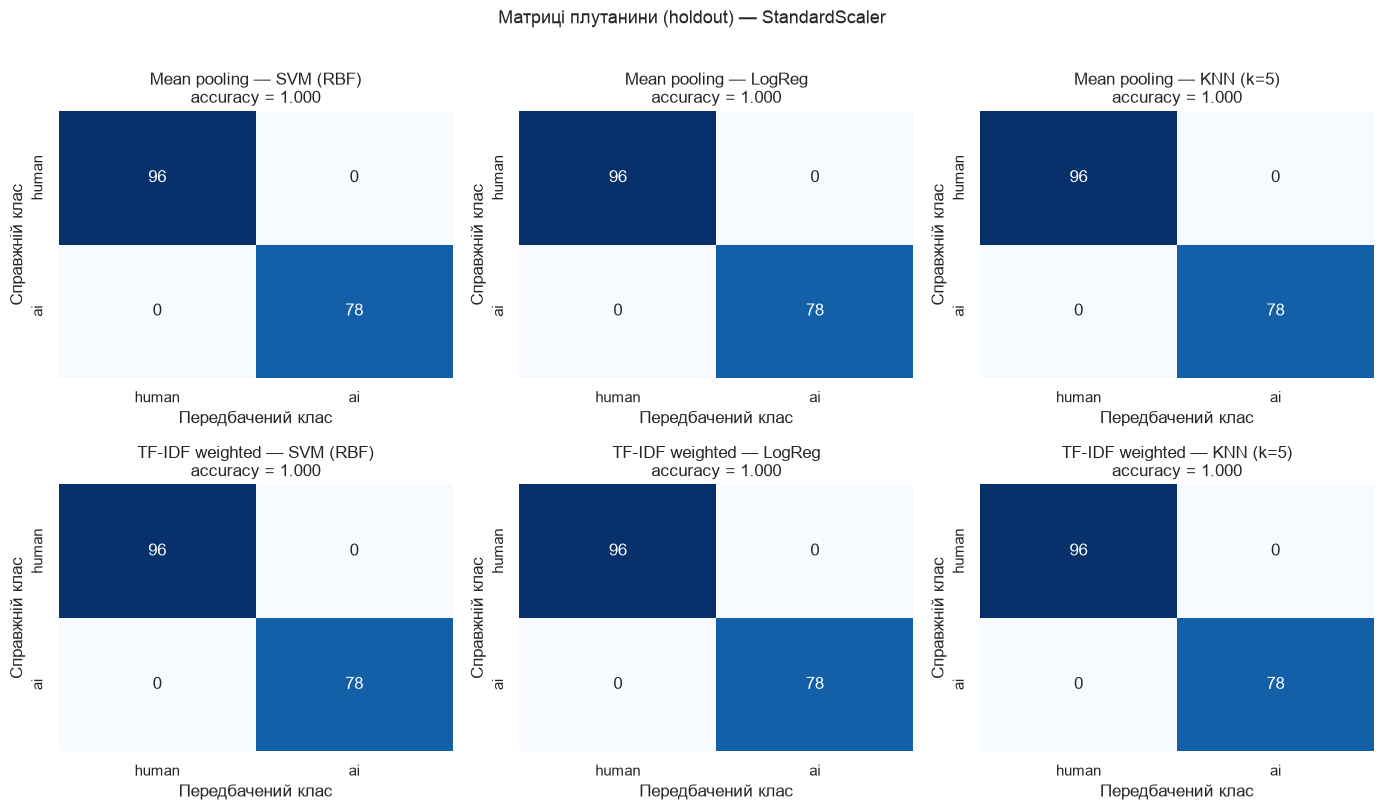

In [57]:
def plot_confusions(scale: bool):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for r, agg in enumerate(REPS):
        for c, name in enumerate(CLF_NAMES):
            cm = confusions[(scale, agg, name)]
            sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[r, c],
                        xticklabels=["human", "ai"], yticklabels=["human", "ai"])
            acc = np.trace(cm) / cm.sum()
            axes[r, c].set_title(f"{agg} — {name}\naccuracy = {acc:.3f}")
            axes[r, c].set_xlabel("Передбачений клас"); axes[r, c].set_ylabel("Справжній клас")
    fig.suptitle(f"Матриці плутанини (holdout) — {SC1 if scale else SC0}", y=1.01, fontsize=13)
    plt.tight_layout(); plt.show()

plot_confusions(False)
plot_confusions(True)

## Лінгвістична інтерпретація: які слова та n-грами маркують клас AI?

Для кожного терма порівнюємо **середнє значення TF-IDF у документах класу AI та Human**. Щоб не інтерпретувати випадкові рідкісні слова, показуємо також **документну частоту** (`df`) у кожному класі та відфільтровуємо терми з сумарною `df < 5`. Аналіз виконано на трьох рівнях: леми (слова), біграми лем та символьні $n$-грами (3–5).

1) Слова з НАЙБІЛЬШИМ середнім TF-IDF у класі AI (абсолютно):


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
464,think,0.0313,0.0000,26,0,0.0313
94,conversation,0.0240,0.0088,68,27,0.0152
332,potential,0.0208,0.0000,42,0,0.0208
325,point,0.0205,0.0094,64,26,0.0111
58,challenge,0.0199,0.0123,118,85,0.0076
346,progress,0.0194,0.0000,42,0,0.0194
169,follow,0.0194,0.0000,42,0,0.0194
306,open,0.0191,0.0000,47,0,0.0191
368,reduce,0.0189,0.0000,22,0,0.0189
75,complexity,0.0189,0.0000,22,0,0.0189


2) Слова, де AI випереджає Human найбільше (AI − Human):


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
464,think,0.0313,0.0,26,0,0.0313
332,potential,0.0208,0.0,42,0,0.0208
346,progress,0.0194,0.0,42,0,0.0194
169,follow,0.0194,0.0,42,0,0.0194
306,open,0.0191,0.0,47,0,0.0191
3,acknowledge,0.0189,0.0,22,0,0.0189
368,reduce,0.0189,0.0,22,0,0.0189
75,complexity,0.0189,0.0,22,0,0.0189
154,exhausting,0.0189,0.0,22,0,0.0189
220,instead,0.0189,0.0,22,0,0.0189


3) Слова, де Human випереджає AI найбільше:


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
457,tell,0.0000,0.0260,0,55,-0.0260
25,argue,0.0000,0.0253,0,88,-0.0253
251,like,0.0000,0.0246,0,53,-0.0246
182,get,0.0000,0.0240,0,54,-0.0240
418,sell,0.0000,0.0234,0,26,-0.0234
76,complicated,0.0000,0.0234,0,26,-0.0234
487,update,0.0000,0.0234,0,26,-0.0234
405,say,0.0000,0.0200,0,55,-0.0200
482,understand,0.0000,0.0190,0,56,-0.0190
234,investigation,0.0000,0.0178,0,88,-0.0178


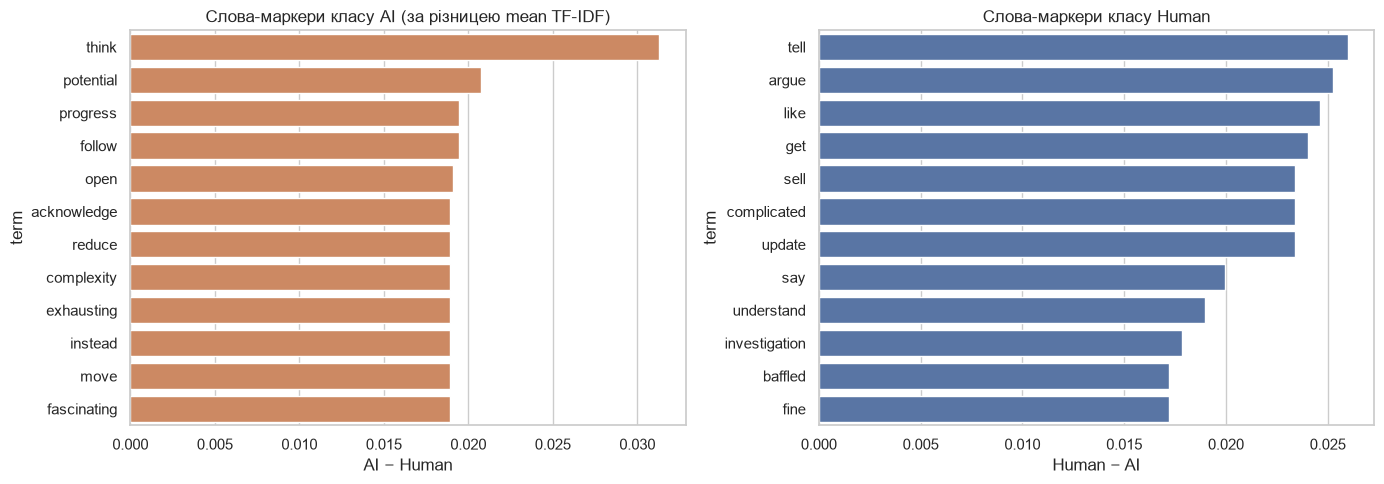

In [58]:
def term_table(matrix, names, labels, min_df: int = 5) -> pd.DataFrame:
    '''Середній TF-IDF за класами, різниця та документні частоти.'''
    ai, hu = matrix[labels == 1], matrix[labels == 0]
    tab = pd.DataFrame({
        "term": names,
        "mean TF-IDF (AI)": np.asarray(ai.mean(axis=0)).ravel(),
        "mean TF-IDF (Human)": np.asarray(hu.mean(axis=0)).ravel(),
        "df (AI)": np.asarray((ai > 0).sum(axis=0)).ravel(),
        "df (Human)": np.asarray((hu > 0).sum(axis=0)).ravel(),
    })
    tab["AI − Human"] = tab["mean TF-IDF (AI)"] - tab["mean TF-IDF (Human)"]
    return tab[(tab["df (AI)"] + tab["df (Human)"]) >= min_df].reset_index(drop=True)


TOP = 15
word_tab = term_table(tfidf_matrix, terms, y)
top_ai_mean = word_tab.sort_values("mean TF-IDF (AI)", ascending=False).head(TOP)
top_ai_diff = word_tab.sort_values("AI − Human", ascending=False).head(TOP)
top_hu_diff = word_tab.sort_values("AI − Human").head(TOP)

print("1) Слова з НАЙБІЛЬШИМ середнім TF-IDF у класі AI (абсолютно):")
display(top_ai_mean.round(4))
print("2) Слова, де AI випереджає Human найбільше (AI − Human):")
display(top_ai_diff.round(4))
print("3) Слова, де Human випереджає AI найбільше:")
display(top_hu_diff.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top_ai_diff.head(12), y="term", x="AI − Human", color="#DD8452", ax=axes[0])
axes[0].set_title("Слова-маркери класу AI (за різницею mean TF-IDF)")
sns.barplot(data=top_hu_diff.head(12).assign(**{"Human − AI": lambda t: -t["AI − Human"]}), y="term", x="Human − AI", color="#4C72B0", ax=axes[1])
axes[1].set_title("Слова-маркери класу Human")
plt.tight_layout(); plt.show()

In [59]:
token_documents = [" ".join(t) for t in df["tokens"]]

# Біграми лем
bi_vec = TfidfVectorizer(ngram_range=(2, 2), token_pattern=r"(?u)\b\w+\b", lowercase=False, min_df=2)
bi_mat = bi_vec.fit_transform(token_documents)
bi_tab = term_table(bi_mat, bi_vec.get_feature_names_out(), y)

# Символьні n-грами (3–5) по сирому тексту, всередині меж слів
ch_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), lowercase=True, min_df=5, sublinear_tf=True)
ch_mat = ch_vec.fit_transform(df["text_content"])
ch_tab = term_table(ch_mat, ch_vec.get_feature_names_out(), y)

for title, tab in [("Біграми лем", bi_tab), ("Символьні n-грами (3–5)", ch_tab)]:
    print(f"── {title}: найсильніші маркери AI ──")
    display(tab.sort_values("AI − Human", ascending=False).head(12).round(4))
    print(f"── {title}: найсильніші маркери Human ──")
    display(tab.sort_values("AI − Human").head(12).round(4))

── Біграми лем: найсильніші маркери AI ──


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
3,acknowledge complexity,0.0201,0.0,22,0,0.0201
571,talk point,0.0201,0.0,22,0,0.0201
285,instead reduce,0.0201,0.0,22,0,0.0201
465,reduce talk,0.0201,0.0,22,0,0.0201
100,complexity instead,0.0201,0.0,22,0,0.0201
202,exhausting acknowledge,0.0201,0.0,22,0,0.0201
449,quickly thing,0.0201,0.0,22,0,0.0201
421,potential approach,0.0201,0.0,22,0,0.0201
215,fascinating quickly,0.0201,0.0,22,0,0.0201
27,approach thoughtfully,0.0201,0.0,22,0,0.0201


── Біграми лем: найсильніші маркери Human ──


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
22,announcement come,0.0,0.0271,0,62,-0.0271
32,argue premature,0.0,0.0271,0,62,-0.0271
563,supporter long,0.0,0.0271,0,62,-0.0271
499,response divide,0.0,0.0271,0,62,-0.0271
541,speculation critic,0.0,0.0271,0,62,-0.0271
127,critic argue,0.0,0.0271,0,62,-0.0271
426,predictable line,0.0,0.0271,0,62,-0.0271
92,come week,0.0,0.0271,0,62,-0.0271
443,public response,0.0,0.0271,0,62,-0.0271
429,premature supporter,0.0,0.0271,0,62,-0.0271


── Символьні n-грами (3–5): найсильніші маркери AI ──


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
2268,eco,0.0160,0.0022,166,30,0.0138
5565,reco,0.0126,0.0000,126,0,0.0126
751,reco,0.0126,0.0000,126,0,0.0126
749,rec,0.0137,0.0016,146,28,0.0121
2480,end,0.0129,0.0012,133,14,0.0118
2269,ecom,0.0116,0.0000,124,0,0.0116
4528,ning,0.0120,0.0019,141,29,0.0102
4527,nin,0.0120,0.0019,141,29,0.0102
3562,ing,0.0267,0.0166,387,330,0.0101
657,op,0.0099,0.0000,86,0,0.0099


── Символьні n-грами (3–5): найсильніші маркери Human ──


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
5156,ove,0.0028,0.0154,39,178,-0.0126
485,is,0.0055,0.0172,105,308,-0.0117
263,do,0.0016,0.0133,21,162,-0.0117
1986,d.,0.0000,0.0111,0,140,-0.0111
4577,not,0.0000,0.0107,0,110,-0.0107
3670,is,0.0099,0.0206,215,451,-0.0106
1562,ay,0.0040,0.0146,40,143,-0.0106
4431,ned,0.0016,0.0120,18,82,-0.0103
4430,ned,0.0016,0.0120,18,82,-0.0103
1412,arg,0.0000,0.0101,0,116,-0.0101


In [60]:
# Перевірка за апріорним списком «типових» LLM-маркерів (евристика, складена ДО перегляду результатів)
LLM_MARKERS = ["furthermore", "moreover", "additionally", "underscore", "highlight", "delve", "comprehensive",
               "multifaceted", "pivotal", "crucial", "robust", "holistic", "leverage", "foster", "facilitate",
               "stakeholder", "framework", "landscape", "nuanced", "ultimately", "notably", "navigate",
               "significant", "sustainable", "challenge", "opportunity", "implication", "consideration"]
present = word_tab[word_tab["term"].isin(LLM_MARKERS)].sort_values("AI − Human", ascending=False)
print(f"З {len(LLM_MARKERS)} апріорних маркерів у словнику (df ≥ 5) знайдено {len(present)}; "
      f"з них частіше в AI-текстах: {int((present['AI − Human'] > 0).sum())}.")
display(present.round(4))

З 28 апріорних маркерів у словнику (df ≥ 5) знайдено 13; з них частіше в AI-текстах: 12.


,term,mean TF-IDF (AI),mean TF-IDF (Human),df (AI),df (Human),AI − Human
435,stakeholder,0.0152,0.0000,60,0,0.0152
481,underscore,0.0151,0.0000,66,0,0.0151
173,framework,0.0174,0.0042,66,29,0.0132
307,opportunity,0.0110,0.0000,19,0,0.0110
424,significant,0.0140,0.0044,67,30,0.0096
77,comprehensive,0.0084,0.0000,21,0,0.0084
193,highlight,0.0084,0.0000,21,0,0.0084
58,challenge,0.0199,0.0123,118,85,0.0076
296,nuanced,0.0124,0.0054,26,28,0.0070
452,sustainable,0.0069,0.0000,24,0,0.0069


## Критична перевірка: прості базові моделі та оцінка без витоку інформації

**Базові моделі** відповідають на питання «чи не вирішується задача тривіальними ознаками?». Якщо довжина тексту або домен вже дають високий Macro F1, то складні ембеддінги не обов'язково «бачать» стиль ШІ.
**Перевірка без витоку:** FastText та IDF навчаються лише на train-частині; test-документи потім лише перетворюються (OOV-слова — через n-грами, невідомі для IDF терми отримують максимальний idf).

In [61]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_macro_f1(pipe, X):
    return float(cross_val_score(pipe, X, y, cv=skf, scoring="f1_macro").mean())


baselines = {}
meta = df[["word_count", "char_count", "avg_sentence_length"]].to_numpy(dtype=float)
baselines["Лише довжини (слова, символи, довж. речення) + LogReg"] = cv_macro_f1(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), meta)
if df["domain"].nunique() > 1:
    baselines["Лише домен (one-hot) + LogReg"] = cv_macro_f1(
        make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000)), df[["domain"]])
baselines["Bag-of-words TF-IDF (розріджений) + LogReg"] = cv_macro_f1(
    make_pipeline(TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False), LogisticRegression(max_iter=1000)),
    np.array(token_documents, dtype=object))
baselines["Mean Pooling FastText + LogReg (для порівняння)"] = float(cv_fold_scores[(False, AGG_M, "LogReg")].mean())
baselines["TF-IDF Weighted FastText + LogReg (для порівняння)"] = float(cv_fold_scores[(False, AGG_T, "LogReg")].mean())
baseline_df = pd.Series(baselines, name="Macro F1 (CV)").to_frame()
display(baseline_df.style.format("{:.3f}"))

,Macro F1 (CV)
"Лише довжини (слова, символи, довж. речення) + LogReg",0.662
Лише домен (one-hot) + LogReg,0.534
Bag-of-words TF-IDF (розріджений) + LogReg,1.000
Mean Pooling FastText + LogReg (для порівняння),0.949
TF-IDF Weighted FastText + LogReg (для порівняння),0.952


In [62]:
# ── Перевірка без витоку: FastText + IDF лише на train ──
train_tokens = [df["tokens"].iloc[i] for i in idx_train]
test_tokens = [df["tokens"].iloc[i] for i in idx_test]

ft_train = FastText(sentences=train_tokens, vector_size=100, window=5, min_count=2, sg=1,
                    workers=4, seed=SEED, epochs=10)
cv_tr = CountVectorizer(analyzer=lambda doc: doc)
cnt_tr = cv_tr.fit_transform(train_tokens)
df_tr = np.asarray((cnt_tr > 0).sum(axis=0)).ravel()
idf_tr = dict(zip(cv_tr.get_feature_names_out(), np.log(len(train_tokens) / df_tr)))

Xtr_m, Xtr_t = vectorize_documents(train_tokens, ft_train, idf_tr, float(np.log(len(train_tokens))))
Xte_m, Xte_t = vectorize_documents(test_tokens, ft_train, idf_tr, float(np.log(len(train_tokens))))

rows = []
for agg, (Xa, Xb) in {AGG_M: (Xtr_m, Xte_m), AGG_T: (Xtr_t, Xte_t)}.items():
    for name, clf in make_classifiers(False).items():
        clf.fit(Xa, y_train)
        pred = clf.predict(Xb)
        rows.append({"Агрегація": agg, "Класифікатор": name,
                     "Macro F1 (без витоку)": f1_score(y_test, pred, average="macro"),
                     "ROC-AUC (без витоку)": roc_auc_score(y_test, clf.predict_proba(Xb)[:, 1])})
leak_free = pd.DataFrame(rows)
cmp = leak_free.merge(res0[["Агрегація", "Класифікатор", "Macro F1", "ROC-AUC"]], on=["Агрегація", "Класифікатор"])
cmp = cmp.rename(columns={"Macro F1": "Macro F1 (основний)", "ROC-AUC": "ROC-AUC (основний)"})
display(cmp.style.format({c: "{:.3f}" for c in cmp.columns if "F1" in c or "AUC" in c}))

Агрегація: 100%|██████████| 174/174 [00:00<00:00, 23990.30док/s]


,Агрегація,Класифікатор,Macro F1 (без витоку),ROC-AUC (без витоку),Macro F1 (основний),ROC-AUC (основний)
0,Mean pooling,SVM (RBF),1.000,1.000,1.000,1.000
1,Mean pooling,LogReg,0.936,0.987,0.948,0.996
2,Mean pooling,KNN (k=5),1.000,1.000,1.000,1.000
3,TF-IDF weighted,SVM (RBF),1.000,1.000,1.000,1.000
4,TF-IDF weighted,LogReg,0.948,0.991,0.959,0.997
5,TF-IDF weighted,KNN (k=5),1.000,1.000,1.000,1.000


## Звіт: обґрунтовані відповіді на дослідницькі питання

Нижче текст відповідей **збирається з фактичних результатів цього запуску** (таблиці вище), а теоретичні пояснення механізмів подано як інтерпретація цих чисел. Поріг «істотної» різниці — 0.01 за Macro F1 і, водночас, більше за розкид між фолдами.

In [63]:
EPS = 0.01


def trend(d: float, noise: float = 0.0) -> str:
    if abs(d) <= max(EPS, noise):
        return "практично не змінює"
    return "покращує" if d > 0 else "погіршує"


def f1_of(scale_label, agg, clf, metric="Macro F1"):
    r = results_all[(results_all["Масштабування"] == scale_label) & (results_all["Агрегація"] == agg)
                    & (results_all["Класифікатор"] == clf)]
    return float(r[metric].iloc[0])


def cv_of(scale, agg, clf):
    return float(cv_fold_scores[(scale, agg, clf)].mean())


def cvd(scale, clf, col="Δ Macro F1 (середнє)"):
    r = cv_delta[(cv_delta["scale"] == scale) & (cv_delta["Класифікатор"] == clf)]
    return float(r[col].iloc[0])


def geo(metric, agg):
    return float(geom_df.loc[metric, agg])


def arrow(metric, digits=3):
    a, b = geo(metric, AGG_M), geo(metric, AGG_T)
    return f"{a:.{digits}f} → {b:.{digits}f}"


def best_row(agg, scale_label=SC0):
    sub = results_all[(results_all["Агрегація"] == agg) & (results_all["Масштабування"] == scale_label)]
    return sub.sort_values(["Macro F1", "ROC-AUC"], ascending=False).iloc[0]


n_test = len(idx_test)
ceiling = min(cv_of(False, AGG_M, "LogReg"), cv_of(False, AGG_T, "LogReg")) >= 0.98
R = []   # рядки Markdown

if FALLBACK_USED:
    R.append("> ⚠️ **Усі числа нижче отримані на СИНТЕТИЧНИХ даних (CSV не знайдено) і не є науковим результатом.** "
             "Покладіть `ai_vs_human_text_2026.csv` поруч із ноутбуком і перезапустіть його.\n")

best_overall = results_all[results_all["Масштабування"] == SC0].sort_values(["Macro F1", "ROC-AUC"], ascending=False).iloc[0]
R.append(f"**Найкраща конфігурація (holdout, основний експеримент):** {best_overall['Агрегація']} + {best_overall['Класифікатор']} "
         f"(Macro F1 = {best_overall['Macro F1']:.3f}, ROC-AUC = {best_overall['ROC-AUC']:.3f}). "
         f"Розмір тесту — {n_test} документів, тож один помилково класифікований документ зсуває Accuracy приблизно на {100 / n_test:.2f} в.п.\n")

# ─────────── 1. Вплив агрегації ───────────
d_lr, s_lr = cvd(False, "LogReg"), cvd(False, "LogReg", "Δ std")
d_all_cv = float(np.mean([cvd(False, c) for c in CLF_NAMES]))
d_all_hold = float(np.mean([f1_of(SC0, AGG_T, c) - f1_of(SC0, AGG_M, c) for c in CLF_NAMES]))
cos_m, cos_t = geo("Середня косинусна подібність", AGG_M), geo("Середня косинусна подібність", AGG_T)
sil_m, sil_t = geo("Silhouette за класами (евкл.)", AGG_M), geo("Silhouette за класами (евкл.)", AGG_T)
bw_m, bw_t = geo("Відстань між класами / всередині класів", AGG_M), geo("Відстань між класами / всередині класів", AGG_T)

R.append("### 1. Вплив агрегації: як TF-IDF змінює геометрію простору порівняно з Mean Pooling?")
R.append(f"* **Що змінилось у геометрії.** Середня косинусна подібність між документами: {arrow('Середня косинусна подібність')} "
         f"({'простір став менш анізотропним — вектори «розійшлись»' if cos_t < cos_m - 0.01 else 'простір став анізотропнішим' if cos_t > cos_m + 0.01 else 'анізотропія майже не змінилась'}); "
         f"частка дисперсії PC1: {arrow('Частка дисперсії PC1')}; ефективна розмірність: {arrow('Ефективна розмірність (participation ratio)', 1)}; "
         f"середня норма вектора: {arrow('Середня норма вектора')}.")
R.append(f"* **Роздільність класів у просторі.** Відношення міжкласових до внутрішньокласових відстаней: {arrow('Відстань між класами / всередині класів', 4)}; "
         f"silhouette за мітками (евкл.): {arrow('Silhouette за класами (евкл.)', 4)} — "
         f"{'зважування підвищило геометричну роздільність класів' if sil_t > sil_m + 0.005 else 'зважування знизило геометричну роздільність класів' if sil_t < sil_m - 0.005 else 'геометрична роздільність практично однакова'}.")
R.append("* **Механізм.** Обидва документні вектори є опуклими комбінаціями **тих самих** слівних векторів. Mean Pooling дає однакову вагу кожному токену, тож у ньому домінують частіші слова, спільні для обох класів, — це створює спільний «зсув» (середній вектор корпусу) та високу косинусну подібність усіх документів. "
         "TF-IDF перерозподіляє ваги на користь термів із великим IDF, тож вектор відхиляється від цього спільного напрямку у бік рідкісної лексики; корисним це буде лише тоді, коли саме такі терми відрізняють класи.")
if ceiling:
    R.append(f"* **Вплив на лінійну роздільність.** Logistic Regression на обох представленнях досягає Macro F1 ≥ 0.98 (CV: {cv_of(False, AGG_M, 'LogReg'):.3f} проти {cv_of(False, AGG_T, 'LogReg'):.3f}), "
             f"тобто класи вже **лінійно роздільні** при простому Mean Pooling, і TF-IDF не має куди покращувати — спостерігається ефект «стелі» (Δ = {d_lr:+.4f}). Це не доводить марності TF-IDF взагалі, а говорить про легкість цього конкретного датасету.")
else:
    R.append(f"* **Вплив на лінійну роздільність.** Для Logistic Regression ΔMacro F1 (CV, TF-IDF − Mean) = {d_lr:+.4f} ± {s_lr:.4f}: зважування **{trend(d_lr, s_lr)}** лінійну роздільність. "
             f"Середнє ΔMacro F1 за всіма трьома класифікаторами: {d_all_cv:+.4f} (CV) і {d_all_hold:+.4f} (holdout).")
R.append("")

# ─────────── 2. Порівняння класифікаторів ───────────
R.append("### 2. Порівняння класифікаторів")
for agg in REPS:
    b = best_row(agg)
    R.append(f"* **{agg}:** найкращий на holdout — **{b['Класифікатор']}** (Macro F1 = {b['Macro F1']:.3f}, ROC-AUC = {b['ROC-AUC']:.3f}). "
             f"Середній Macro F1 у CV: SVM {cv_of(False, agg, 'SVM (RBF)'):.3f}, LogReg {cv_of(False, agg, 'LogReg'):.3f}, KNN {cv_of(False, agg, 'KNN (k=5)'):.3f}.")
gap = float(np.mean([cv_of(False, a, "SVM (RBF)") - cv_of(False, a, "LogReg") for a in REPS]))
if abs(gap) <= EPS:
    nat = (f"SVM з RBF-ядром і лінійна LogReg дають практично однакову якість (різниця {gap:+.3f}): нелінійне ядро нічого не додає, "
           "отже межа між класами в цьому просторі **по суті лінійна**.")
elif gap > 0:
    nat = (f"SVM (RBF) випереджає LogReg у середньому на {gap:.3f}: є **нелінійна структура**, яку лінійна межа не вловлює; "
           "RBF-ядро краще підлаштовується під локальні скупчення документів.")
else:
    nat = (f"LogReg не гірша за SVM (RBF) (різниця SVM−LogReg = {gap:+.3f}): складніша нелінійна модель не виправдовується — "
           "класи лінійно роздільні, а гнучкість RBF лише додає ризик перенавчання.")
R.append(f"* **Зв'язок із природою даних.** {nat}")
knn_gap = float(np.mean([cv_of(False, a, "KNN (k=5)") - max(cv_of(False, a, "SVM (RBF)"), cv_of(False, a, "LogReg")) for a in REPS]))
if knn_gap < -EPS:
    R.append(f"* **KNN** у середньому відстає від найкращої з двох інших моделей на {-knn_gap:.3f} (без масштабування): KNN повністю залежить від метрики простору, тоді як SVM/LogReg здатні «перевзважити» ознаки через навчені параметри.\n")
else:
    R.append(f"* **KNN** за якістю не відрізняється суттєво від найкращої з двох інших моделей (різниця {knn_gap:+.3f}): у цьому просторі локальна структура сусідства вже узгоджена з мітками класів.\n")

# ─────────── 3. Чутливість KNN ───────────
dk_hold = f1_of(SC0, AGG_T, "KNN (k=5)") - f1_of(SC0, AGG_M, "KNN (k=5)")
dk_cv, dk_std = cvd(False, "KNN (k=5)"), cvd(False, "KNN (k=5)", "Δ std")
dk_cv_sc = cvd(True, "KNN (k=5)")
pur_m, pur_t = geo("Чистота 5-NN (без масштабування)", AGG_M), geo("Чистота 5-NN (без масштабування)", AGG_T)
R.append("### 3. Чутливість KNN: чому можлива деградація при переході до TF-IDF?")
R.append(f"* **Результат.** ΔMacro F1 для KNN (TF-IDF − Mean): holdout {dk_hold:+.3f}, CV {dk_cv:+.4f} ± {dk_std:.4f}; зі StandardScaler (CV) {dk_cv_sc:+.4f}. "
         f"Висновок: TF-IDF зважування **{trend(dk_cv, dk_std)}** якість KNN у даному експерименті.")
R.append(f"* **Геометричні докази.** Чистота 5-NN (частка сусідів того ж класу): {arrow('Чистота 5-NN (без масштабування)', 4)}; після StandardScaler: {arrow('Чистота 5-NN (після StandardScaler)', 4)}. "
         f"Концентрація відстаней — коефіцієнт варіації відстаней: {arrow('Коеф. варіації відстаней (std/mean)', 4)}, контраст сусідства (відстань до найближчого / середня відстань): {arrow('Контраст сусідства (d найближчого / d середня)', 3)}; "
         f"коефіцієнт варіації норм векторів: {arrow('Коеф. варіації норм (std/mean)', 4)}.")
R.append("* **Механізм (теоретичне пояснення).** У 100-вимірному просторі евклідові відстані схильні концентруватися (прокляття розмірності): відстані до найближчого й найдальшого сусіда стають співмірними, і «найближчі» сусіди стають менш інформативними. "
         "TF-IDF-зважування додатково змінює *метричні властивості*: ваги концентруються на небагатьох рідкісних токенах, тож норми й розкид координат документів стають менш однорідними, і евклідова відстань починає відображати не лише напрямок (зміст), а й норму та шум від рідкісних слів. "
         "Для KNN, який не вчить параметрів, зміна метрики напряму змінює список сусідів, тому він найчутливіший до способу агрегації. "
         + ("У цьому запуску частка однокласових сусідів справді впала — це узгоджується з деградацією." if pur_t < pur_m - 0.01 else "У цьому запуску частка однокласових сусідів суттєво не змінилась, тож деградації KNN не спостерігається — теоретичний ризик не реалізувався на цих даних."))
R.append(f"* **Роль масштабування.** StandardScaler вирівнює дисперсії координат; для KNN це змінило Δ з {dk_cv:+.4f} (без масштабування) до {dk_cv_sc:+.4f} (зі масштабуванням) — "
         f"{'тобто частина різниці зумовлена саме масштабом ознак, а не «змістом» агрегації' if abs(dk_cv_sc - dk_cv) > 0.005 else 'тобто в цьому наборі масштабування практично не впливає на висновок'}.\n")

# ─────────── 4. Лінгвістична інтерпретація ───────────
k_words = ", ".join(top_ai_diff["term"].head(10))
k_hum = ", ".join(top_hu_diff["term"].head(10))
only_ai = int((top_ai_diff.head(10)["df (Human)"] == 0).sum())
top_bi = ", ".join(bi_tab.sort_values("AI − Human", ascending=False)["term"].head(6))
top_ch = ", ".join(f"«{t}»" for t in ch_tab.sort_values("AI − Human", ascending=False)["term"].head(8))
n_mark = int((present["AI − Human"] > 0).sum())
R.append("### 4. Лінгвістична інтерпретація: що є маркерами штучного тексту?")
R.append(f"* **Слова з найбільшою перевагою TF-IDF у класі AI:** {k_words}. **У класі Human:** {k_hum}.")
R.append(f"* **Біграми лем (AI):** {top_bi}. **Символьні n-грами (AI):** {top_ch}.")
R.append(f"* Із 10 найсильніших AI-слів **{only_ai}** не трапляються у жодному human-тексті (df(Human) = 0) — "
         f"{'це радше шаблонні лексичні «відбитки» конкретного генератора/промпту, ніж плавна стилістична відмінність' if only_ai >= 5 else 'це не лише рідкісні слова-«відбитки»: вони мають ненульову частоту і серед людських текстів'}. "
         f"З {len(present)} апріорних LLM-маркерів (furthermore, underscore, stakeholder, comprehensive…), що є у словнику, частіше в AI-текстах трапляються {n_mark}.")
R.append(f"* **Чи можна вважати їх маркерами ШІ?** Лише з обережністю. Прості базові моделі показують: лише довжини дають Macro F1 = {baselines['Лише довжини (слова, символи, довж. речення) + LogReg']:.3f}"
         + (f", лише домен — {baselines['Лише домен (one-hot) + LogReg']:.3f}" if 'Лише домен (one-hot) + LogReg' in baselines else "")
         + f", мішок слів — {baselines['Bag-of-words TF-IDF (розріджений) + LogReg']:.3f}. Якщо ці числа високі, значить частина сигналу — це тема/регістр/довжина, а не «стиль ШІ». "
           "Слова на кшталт *stakeholder, framework, recommendation* відображають формальний регістр, а не фундаментальну властивість машинного тексту; інший генератор або інший промпт цей «відбиток» зітре.\n")

# ─────────── 5. Геометричний аналіз (t-SNE) ───────────
ts = tsne_quality
sl_m, sl_t = float(ts.loc[AGG_M, "Silhouette 2D (клас)"]), float(ts.loc[AGG_T, "Silhouette 2D (клас)"])
pl_m, pl_t = float(ts.loc[AGG_M, "Чистота 5-NN 2D (клас)"]), float(ts.loc[AGG_T, "Чистота 5-NN 2D (клас)"])
better = AGG_T if (sl_t + pl_t) > (sl_m + pl_m) + 0.01 else AGG_M if (sl_m + pl_m) > (sl_t + pl_t) + 0.01 else None
compact = "так, класи утворюють чіткі окремі скупчення" if max(sl_m, sl_t) > 0.3 else "частково: скупчення помітні, але перекриваються" if max(sl_m, sl_t) > 0.1 else "ні: класи значно перекриваються"
R.append("### 5. Геометричний аналіз (t-SNE)")
R.append(f"* **Чи утворюють класи компактні кластери?** {compact}. Silhouette у 2D за класами: Mean {sl_m:.3f}, TF-IDF {sl_t:.3f}; чистота 5-NN у 2D: {pl_m:.3f} та {pl_t:.3f}.")
R.append(f"* **Який метод агрегації кращий за кластеризацією?** "
         + (f"**{better}** (вищі silhouette та чистота сусідів)." if better else "різниця між методами в межах похибки — візуально й числово кластеризація однакова."))
if has_domain:
    sd_m, sd_t = float(ts.loc[AGG_M, "Silhouette 2D (домен)"]), float(ts.loc[AGG_T, "Silhouette 2D (домен)"])
    R.append(f"* **Конфаундер «домен».** Silhouette у 2D за доменом: Mean {sd_m:.3f}, TF-IDF {sd_t:.3f} (за класом: {sl_m:.3f} та {sl_t:.3f}). "
             f"{'Структура проєкції сильніше відповідає домену, ніж класу — класифікатор ризикує вчити тему/регістр.' if max(sd_m, sd_t) > max(sl_m, sl_t) else 'Домен структурує проєкцію слабше, ніж клас.'}")
R.append("* t-SNE — нелінійна візуалізація: вона лише ілюструє, але не доводить роздільність. Опорою є числові метрики якості (етапи 5–6).\n")

# ─────────── Гіпотеза ───────────
R.append("### Перевірка дослідницької гіпотези")
if ceiling:
    verdict = (f"**Гіпотезу не вдалося ні підтвердити, ні спростувати** — обидва представлення вже дають Macro F1 ≥ 0.98 для лінійного класифікатора (ефект стелі), "
               f"тому TF-IDF не має простору для покращення (Δ = {d_lr:+.4f}).")
elif d_lr > max(EPS, s_lr):
    verdict = f"**Гіпотезу підтверджено** для лінійної моделі: TF-IDF покращує Macro F1 LogReg на {d_lr:+.4f} (більше за розкид між фолдами {s_lr:.4f})."
elif d_lr < -max(EPS, s_lr):
    verdict = f"**Гіпотезу спростовано** на цих даних: TF-IDF погіршує Macro F1 LogReg на {d_lr:+.4f}."
else:
    verdict = f"**Гіпотезу не підтверджено:** різниця (Δ = {d_lr:+.4f} ± {s_lr:.4f}) у межах шуму між фолдами."
R.append(verdict + "\n")

# ─────────── Обмеження ───────────
lf_gap = float((cmp["Macro F1 (без витоку)"] - cmp["Macro F1 (основний)"]).abs().max())
R.append("### Обмеження дослідження")
R.append(f"1. **Штучність даних.** {'Колонка generation_method повністю збігається з класом: Human-тексти створені за шаблонами «template + human variation», AI-тексти — за «style simulation». Це закладає жорсткі синтаксичні й лексичні відбитки та робить межу штучно чіткою. ' if perfect_gm else ''}"
         "Результати описують цей датасет і не доводять здатності виявляти тексти невідомих моделей, тем чи доменів.")
R.append(f"2. **Короткі тексти.** Медіана — {df['word_count'].median():.0f} слів; більшість термів зустрічається в документі один раз, тож TF-IDF діє майже виключно через IDF, а тонкі статистичні ефекти не встигають проявитись.")
R.append(f"3. **Малий тест.** Holdout містить {n_test} документів; різниця менша за 1–2 в.п. не є статистично надійною. Тому додано повторну CV 5×2.")
R.append(f"4. **Витік інформації.** В основному експерименті FastText та IDF навчались на всьому корпусі (без міток). Перевірка «лише на train» змінила Macro F1 щонайбільше на {lf_gap:.3f} — "
         f"{'висновки стійкі' if lf_gap < 0.02 else 'вплив відчутний, тож варто орієнтуватись на перевірку без витоку'}.")
R.append("5. **Конфаундери.** Домен, довжина й тема корелюють із класом; топ-терми — це статистичні відбитки цього датасету, а не універсальні маркери.")
R.append("6. **Відтворюваність.** FastText з `workers=4` недетермінований на рівні потоків; невеликі коливання метрик між запусками можливі.")

display(Markdown("\n".join(R)))

**Найкраща конфігурація (holdout, основний експеримент):** Mean pooling + SVM (RBF) (Macro F1 = 1.000, ROC-AUC = 1.000). Розмір тесту — 174 документів, тож один помилково класифікований документ зсуває Accuracy приблизно на 0.57 в.п.

### 1. Вплив агрегації: як TF-IDF змінює геометрію простору порівняно з Mean Pooling?
* **Що змінилось у геометрії.** Середня косинусна подібність між документами: 0.666 → 0.662 (анізотропія майже не змінилась); частка дисперсії PC1: 0.165 → 0.157; ефективна розмірність: 11.9 → 12.3; середня норма вектора: 2.946 → 2.962.
* **Роздільність класів у просторі.** Відношення міжкласових до внутрішньокласових відстаней: 1.0426 → 1.0448; silhouette за мітками (евкл.): 0.0442 → 0.0455 — геометрична роздільність практично однакова.
* **Механізм.** Обидва документні вектори є опуклими комбінаціями **тих самих** слівних векторів. Mean Pooling дає однакову вагу кожному токену, тож у ньому домінують частіші слова, спільні для обох класів, — це створює спільний «зсув» (середній вектор корпусу) та високу косинусну подібність усіх документів. TF-IDF перерозподіляє ваги на користь термів із великим IDF, тож вектор відхиляється від цього спільного напрямку у бік рідкісної лексики; корисним це буде лише тоді, коли саме такі терми відрізняють класи.
* **Вплив на лінійну роздільність.** Для Logistic Regression ΔMacro F1 (CV, TF-IDF − Mean) = +0.0029 ± 0.0060: зважування **практично не змінює** лінійну роздільність. Середнє ΔMacro F1 за всіма трьома класифікаторами: +0.0010 (CV) і +0.0039 (holdout).

### 2. Порівняння класифікаторів
* **Mean pooling:** найкращий на holdout — **SVM (RBF)** (Macro F1 = 1.000, ROC-AUC = 1.000). Середній Macro F1 у CV: SVM 1.000, LogReg 0.949, KNN 1.000.
* **TF-IDF weighted:** найкращий на holdout — **SVM (RBF)** (Macro F1 = 1.000, ROC-AUC = 1.000). Середній Macro F1 у CV: SVM 1.000, LogReg 0.952, KNN 1.000.
* **Зв'язок із природою даних.** SVM (RBF) випереджає LogReg у середньому на 0.050: є **нелінійна структура**, яку лінійна межа не вловлює; RBF-ядро краще підлаштовується під локальні скупчення документів.
* **KNN** за якістю не відрізняється суттєво від найкращої з двох інших моделей (різниця +0.000): у цьому просторі локальна структура сусідства вже узгоджена з мітками класів.

### 3. Чутливість KNN: чому можлива деградація при переході до TF-IDF?
* **Результат.** ΔMacro F1 для KNN (TF-IDF − Mean): holdout +0.000, CV +0.0000 ± 0.0000; зі StandardScaler (CV) +0.0000. Висновок: TF-IDF зважування **практично не змінює** якість KNN у даному експерименті.
* **Геометричні докази.** Чистота 5-NN (частка сусідів того ж класу): 1.0000 → 1.0000; після StandardScaler: 1.0000 → 1.0000. Концентрація відстаней — коефіцієнт варіації відстаней: 0.2057 → 0.2021, контраст сусідства (відстань до найближчого / середня відстань): 0.102 → 0.106; коефіцієнт варіації норм векторів: 0.0769 → 0.0752.
* **Механізм (теоретичне пояснення).** У 100-вимірному просторі евклідові відстані схильні концентруватися (прокляття розмірності): відстані до найближчого й найдальшого сусіда стають співмірними, і «найближчі» сусіди стають менш інформативними. TF-IDF-зважування додатково змінює *метричні властивості*: ваги концентруються на небагатьох рідкісних токенах, тож норми й розкид координат документів стають менш однорідними, і евклідова відстань починає відображати не лише напрямок (зміст), а й норму та шум від рідкісних слів. Для KNN, який не вчить параметрів, зміна метрики напряму змінює список сусідів, тому він найчутливіший до способу агрегації. У цьому запуску частка однокласових сусідів суттєво не змінилась, тож деградації KNN не спостерігається — теоретичний ризик не реалізувався на цих даних.
* **Роль масштабування.** StandardScaler вирівнює дисперсії координат; для KNN це змінило Δ з +0.0000 (без масштабування) до +0.0000 (зі масштабуванням) — тобто в цьому наборі масштабування практично не впливає на висновок.

### 4. Лінгвістична інтерпретація: що є маркерами штучного тексту?
* **Слова з найбільшою перевагою TF-IDF у класі AI:** think, potential, progress, follow, open, acknowledge, reduce, complexity, exhausting, instead. **У класі Human:** tell, argue, like, get, sell, complicated, update, say, understand, investigation.
* **Біграми лем (AI):** acknowledge complexity, talk point, instead reduce, reduce talk, complexity instead, exhausting acknowledge. **Символьні n-грами (AI):** «eco», «reco», « reco», « rec», «end», «ecom», «ning», «nin».
* Із 10 найсильніших AI-слів **10** не трапляються у жодному human-тексті (df(Human) = 0) — це радше шаблонні лексичні «відбитки» конкретного генератора/промпту, ніж плавна стилістична відмінність. З 13 апріорних LLM-маркерів (furthermore, underscore, stakeholder, comprehensive…), що є у словнику, частіше в AI-текстах трапляються 12.
* **Чи можна вважати їх маркерами ШІ?** Лише з обережністю. Прості базові моделі показують: лише довжини дають Macro F1 = 0.662, лише домен — 0.534, мішок слів — 1.000. Якщо ці числа високі, значить частина сигналу — це тема/регістр/довжина, а не «стиль ШІ». Слова на кшталт *stakeholder, framework, recommendation* відображають формальний регістр, а не фундаментальну властивість машинного тексту; інший генератор або інший промпт цей «відбиток» зітре.

### 5. Геометричний аналіз (t-SNE)
* **Чи утворюють класи компактні кластери?** ні: класи значно перекриваються. Silhouette у 2D за класами: Mean 0.052, TF-IDF 0.056; чистота 5-NN у 2D: 1.000 та 1.000.
* **Який метод агрегації кращий за кластеризацією?** різниця між методами в межах похибки — візуально й числово кластеризація однакова.
* **Конфаундер «домен».** Silhouette у 2D за доменом: Mean 0.372, TF-IDF 0.406 (за класом: 0.052 та 0.056). Структура проєкції сильніше відповідає домену, ніж класу — класифікатор ризикує вчити тему/регістр.
* t-SNE — нелінійна візуалізація: вона лише ілюструє, але не доводить роздільність. Опорою є числові метрики якості (етапи 5–6).

### Перевірка дослідницької гіпотези
**Гіпотезу не підтверджено:** різниця (Δ = +0.0029 ± 0.0060) у межах шуму між фолдами.

### Обмеження дослідження
1. **Штучність даних.** Колонка generation_method повністю збігається з класом: Human-тексти створені за шаблонами «template + human variation», AI-тексти — за «style simulation». Це закладає жорсткі синтаксичні й лексичні відбитки та робить межу штучно чіткою. Результати описують цей датасет і не доводять здатності виявляти тексти невідомих моделей, тем чи доменів.
2. **Короткі тексти.** Медіана — 37 слів; більшість термів зустрічається в документі один раз, тож TF-IDF діє майже виключно через IDF, а тонкі статистичні ефекти не встигають проявитись.
3. **Малий тест.** Holdout містить 174 документів; різниця менша за 1–2 в.п. не є статистично надійною. Тому додано повторну CV 5×2.
4. **Витік інформації.** В основному експерименті FastText та IDF навчались на всьому корпусі (без міток). Перевірка «лише на train» змінила Macro F1 щонайбільше на 0.012 — висновки стійкі.
5. **Конфаундери.** Домен, довжина й тема корелюють із класом; топ-терми — це статистичні відбитки цього датасету, а не універсальні маркери.
6. **Відтворюваність.** FastText з `workers=4` недетермінований на рівні потоків; невеликі коливання метрик між запусками можливі.

## Загальний висновок
Експеримент порівнює два способи агрегації субслівних FastText-векторів (Mean Pooling та TF-IDF Weighted Mean) у трьох класифікаторах (SVM-RBF, Logistic Regression, KNN). Конкретні кількісні висновки (чи покращує TF-IDF лінійну роздільність, як змінюється поведінка KNN, які терми є маркерами AI) сформовані в розділі «Звіт» вище автоматично з отриманих чисел. Загальна методична порада: оцінювати ефект агрегації на кількох розбиттях (CV), відокремлювати вплив масштабу ознак (StandardScaler), контролювати конфаундери (домен, довжина, спосіб генерації) та перевіряти результат на текстах із **інших** моделей і доменів, перш ніж робити висновки про «детекцію ШІ» взагалі.